# 空间转录组多样本整合

In [1]:
from datetime import date
print("Author: Biomamba")
print("Date:", date.today())

Author: Biomamba
Date: 2025-10-15


# 零、欢迎关注**Biomamba 生信基地**

## Biomamba，理学博士，此公众号旨在分享生信知识及科研经验与体会，目前在B站的同名账号中发布的手把手教你做单细胞测序数据分析系列视频点击量已经超过45.8W。同名微信公众号拥有超过五万的关注用户以及超过五百万的访问量。如果需要数据分析指导、生信热点全文复现、自测/数据库数据个性化分析辅导、常态化实验学习，欢迎联系客服微信[Biomamba_yunying]

![./img/Rmarkdown开头2025.jpg](http://biomamba.com:34080/free.download/file.back/biomamba/Rmarkdown%E5%BC%80%E5%A4%B42025.jpg)

# 一、写在前面

## 本教程基于Linux中的jupyter环境演示，计算资源不足的同学可参考：  
[生信分析为什么要使用服务器？](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247491007&idx=1&sn=8619c2bad23791b3252a1c4cb1831931&chksm=9b3f64efac48edf9c02f84959aeee9b12480736fce70c5ddb8b41d79cfc22ce590ea2cb60fba&token=1760636281&lang=zh_CN#rd)\
[足够支持你完成硕博生涯的生信环境](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247511780&idx=1&sn=3acc0874f7d2fa75f1abbe7a9a9b4069&chksm=9b3cd7b4ac4b5ea27d4d53964e4a4a9fa8c806a19103729dd4ff0fa72e621411f46a251d269f&scene=21#wechat_redirect)\
[配置一个心仪的工作站(硬件+环境配置)](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247519707&idx=1&sn=73dcab26f9b2ed75a954327317d07112&chksm=9b3cf48bac4b7d9df5b5a432fbe70d4f9c13bc8d739aa401732614f022223d1912642a7e4bea&scene=21#wechat_redirect)\
[独享服务器，生信分析不求人](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503618&idx=1&sn=ca47ca985aa8560f6b38f15f210519e2&chksm=9b3cb652ac4b3f44292560071b7e98e2f6fa6ec03581cd882a4d59b9d7fa063a5b9ac1b923f3&scene=21#wechat_redirect)\
[为实验室准备一份生物信息学不动产](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247492383&idx=1&sn=b8d912877cb38e8d8c9084d1d9370ded&chksm=9b3c9a4fac4b135926091a8af972c45a17a2fa1f94c704779c60df5f733847036c3797894c1c&scene=21#wechat_redirect)


## Linux和Conda是我们本次课程环境搭建的基础，这两部分我们在前期推送中也有相关内容介绍。如果还没有接触过的同学可以跟随我们[十小时学会Linux](https://mp.weixin.qq.com/s/77IMXW_6QFLpbqSeMLfNJg)、[生信软件管家——conda的安装、使用、卸载](https://mp.weixin.qq.com/s/VwRHks00awHXY1tfoPNX9A)和[利用conda打包/复刻生信环境](https://mp.weixin.qq.com/s/y_NPTabHSDGPw2D-_Izs1A)教程内容提前学习一下。

## jupyter notebook作为Python的集成环境，可以逐行运行Python代码并返回结果，并且支持markerdown语法编译，可以说是一个学习Python的笔记本。jupyter notebook使用可以参考[码Python神器：jupyter notebook](https://mp.weixin.qq.com/s/bK_Ri16z8YG-1ZyRqkhM9A)。


##  Python作为本次课程**核心编程语言**。它语法简洁、库资源丰富，计算高效，是数据科学、自动化开发等领域的首选，兼顾新手入门与资深者高效需求。因此，同学们在学习这个教程前，需要有一定得Python知识，可以参考[生信Python速查手册](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247499921&idx=1&sn=dcd6f95596e3de9bf378d850c217fe78&chksm=9b3cb9c1ac4b30d7bbd44057b181f87541f5904d24f903494ae557e768ae00c208c1b68b45c7&payreadticket=HFPtvn0Hc_3itk_RHA90ykGyhDmPMGdHlmAWpCN5_JoUcbpyL6P82ctGZm0c2MiiBCZcLU0#rd)进行快速学习

# 二、空间多样本整合：应对批次效应的挑战

在空间转录组（Spatial Transcriptomics, ST）研究中，**批次效应（Batch Effect）**是一个核心挑战。当多个样本（来自不同个体、实验室或处理批次）被独立测序时，由于实验条件、试剂差异或组织处理方式的不同，可能会引入非生物学性的表达水平变异。

正如所提到的，如果不同的实验室采用了不同的spot或 RNA **解离方案**，数据中就可能出现明显的差异（例如，表达更多**压力相关基因**）。这些批次效应如果得不到有效校正，将会严重干扰后续的聚类、差异聚类识别和空间模式分析。

![](http://biomamba.com:34080/free.download/file.back/biomamba/chenao/merge1.png)

### 核心目标与工具选择

空间多样本整合的目标是**消除非生物学变异**，同时**保留生物学差异**。

1.  **简单批次效应校正：**
    * 对于结构相对简单、差异较小的批次效应，我们推荐使用传统且表现稳定的方法，如 **Seurat (或 Scanpy 中的 `bbknn` / `Harmony`)**。

2.  **复杂批次效应校正：**
    * 对于涉及复杂细胞类型、非线性数据结构的挑战性整合任务，基于**深度学习**和**概率模型**的方法表现更为出色，例如 **scVI**、**scGen**、**scANVI** 和 **Scanorama**。

### 整合效果的评估标准

为了客观衡量数据整合的效果，我们不能只依赖于定性可视化（如 UMAP）。通常需要采用专门的评估工具包，例如 **scib**。

scib 包整合了 **10 个关键指标**，用于从两大方面评估整合的质量：
* **不同类型分离度：** 衡量整合后不同生物学细胞类型是否仍然能够保持区分度。
* **批次混合度：** 衡量来自不同批次的样本是否在潜空间中被充分混合。

通过这些量化指标，我们可以科学地选择最适合我们数据的校正方法，确保后续空间分析结果的可靠性。

![](http://biomamba.com:34080/free.download/file.back/biomamba/chenao/scib.png)

# 三、代码实操

In [2]:
# 从标准库导入 Path，用于处理文件系统路径，方便地创建、检查和操作文件和目录
from pathlib import Path
# 导入 Scanpy 库，这是空间（单细胞） RNA 测序 (scRNA-seq) 数据分析的核心工具包
import scanpy as sc
print(f"scanpy version: {sc.__version__}")

# 导入 Squidpy 库，这是一个专门用于空间转录组数据的分析工具包
# 它可以处理空间数据，整合组织图像信息，进行空间邻域分析等
import squidpy as sq
print(f"squidpy version: {sq.__version__}")

# 导入 scIB (Single-Cell Integration Benchmark) 库
# 主要用于评估和比较不同空间（单细胞）数据整合方法的性能
import scib
print(f"scib version: {scib.__version__}")
# import sckit as sk
# 导入 Matplotlib 的绘图模块，这是 Python 中最基础且最强大的绘图库
import matplotlib.pyplot as plt

# 导入 NumPy 库，这是 Python 科学计算的核心库，提供了高性能的多维数组对象和工具
# 它是所有科学计算库（如 Scanpy、Pandas 等）的底层基础
import numpy as np

# 重置 Matplotlib 的默认配置参数
# 确保每次绘图都使用一致的、默认的样式设置，避免之前操作的设置影响新的图表。
plt.rcdefaults()

scanpy version: 1.11.4


/home/puddddd/miniconda3/envs/scvi_env/lib/python3.10/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution


squidpy version: 1.6.5
scib version: 1.1.7


/home/puddddd/miniconda3/envs/scvi_env/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


## 1. 导入数据
我们分析所用到的数据中包括了来自两个样本的矢状后和矢状前端，该数据集由10x genomics提供。我们可以在这里下载该数据集：https://www.10xgenomics.com/datasets/mouse-brain-serial-section-1-sagittal-posterior-1-standard-1-0-0；https://www.10xgenomics.com/datasets/mouse-brain-serial-section-1-sagittal-anterior-1-standard-1-1-0

In [3]:
# 将所有样本读取到字典中
adata_dct = {}
for i in Path("/data/06_mutiple_sample_integration/data").glob("**/outs"):
    _s = str(i).split('/')[4]
    _a = sq.read.visium(i, library_id=_s)
    _a.var_names_make_unique()
    adata_dct[_s] = _a

/home/puddddd/miniconda3/envs/scvi_env/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/puddddd/miniconda3/envs/scvi_env/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/puddddd/miniconda3/envs/scvi_env/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/puddddd/miniconda3/envs/scvi_env/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [4]:
# 使用concat合并所有样本
adata = sc.concat(adata_dct,label="library_id",uns_merge="unique")

/home/puddddd/miniconda3/envs/scvi_env/lib/python3.10/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


In [5]:
# 处理合并后的数据，确保obs和var唯一
adata.var_names_make_unique()
adata.obs_names_make_unique()
adata

AnnData object with n_obs × n_vars = 6048 × 29836
    obs: 'in_tissue', 'array_row', 'array_col', 'library_id'
    uns: 'spatial'
    obsm: 'spatial'

In [6]:
# 查看每个样本的spot数
adata.obs['library_id'].value_counts()

library_id
Posterior    3353
Anterior     2695
Name: count, dtype: int64

## 2. 过滤初始数据 （参考基础分析部分）

spots: 6048 | genes: 29836
                    count          mean           std        min  \
total_counts       6048.0  20685.314453  11654.985352  48.000000   
n_genes_by_counts  6048.0   5057.788690   1771.571529  40.000000   
pct_counts_mt      6048.0     13.649095      5.346816   0.811359   
pct_counts_ribo    6048.0      6.453414      1.313510   1.041667   

                            25%           50%           75%           max  
total_counts       11591.500000  19213.500000  28520.250000  74907.000000  
n_genes_by_counts   3832.750000   5239.500000   6436.000000   9106.000000  
pct_counts_mt         10.702832     13.249630     16.116378     43.720718  
pct_counts_ribo        5.544604      6.313347      7.269116     12.786557  


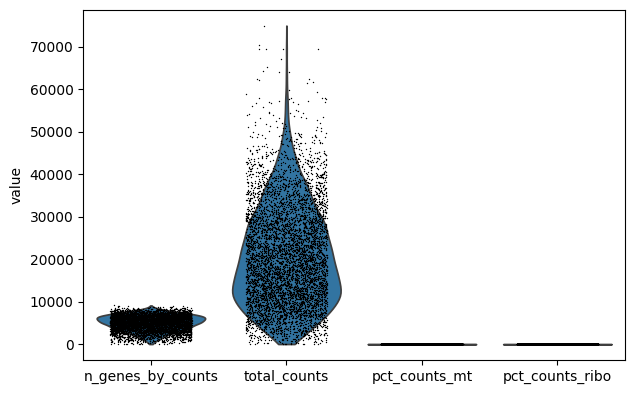

Using min_counts=2348, max_counts=47167


In [7]:
# 当前代码使用的是 `("mt-", "mt.")`，针对小鼠数据编写的
# 如果数据是人类的，你需要将其改为 `("MT-",)`
adata.var["mt"] = adata.var_names.str.startswith(("mt-","mt."))
# 当前代码使用的是 `^(Rps|Rpl)\d`，因此是针对小鼠数据编写的
# 如果数据是人类的，你需要将其改为 `r"^(RPS|RPL)\d"`
# `na=False` 确保如果基因名是缺失值（NaN），它会被标记为 False
adata.var["ribo"] = adata.var_names.str.match(r"^(Rps|Rpl)\d", na=False)
# 计算 QC 指标并直接更新到 AnnData 对象 (adata) 中
# sc.pp.calculate_qc_metrics 是 Scanpy 中用于计算 QC 统计的函数。
# qc_vars=["mt","ribo"]：指定要计算百分比计数的自定义变量，即前面步骤中标记的线粒体基因 (mt) 和核糖体基因 (ribo)。
# inplace=True：表示将计算结果（QC 统计数据）直接添加到 adata.obs（观测值/spot/细胞元数据）中。
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt","ribo"], inplace=True)

# 打印当前 adata 对象中的 Spot 和基因数量
# adata.n_obs：Spot（观测值）的数量
# adata.n_vars：基因（特征）的数量
print("spots:", adata.n_obs, "| genes:", adata.n_vars)

# 打印新生成的 QC 指标的描述性统计摘要
# .describe().T：计算 QC 指标（如均值、标准差、最小值、四分位数等）并转置表格，方便阅读。
print(adata.obs[[
    "total_counts",        # 每个 Spot 的总 UMI 计数（即测序深度）
    "n_genes_by_counts",   # 每个 Spot 检测到的基因总数
    "pct_counts_mt",       # 每个 Spot 中线粒体基因计数占总 UMI 计数的百分比
    "pct_counts_ribo"      # 每个 Spot 中核糖体基因计数占总 UMI 计数的百分比
]].describe().T)
# 绘制初始的指控指标小提琴图
qc_keys = [
    k 
    for k in ["n_genes_by_counts","total_counts","pct_counts_mt","pct_counts_ribo"]
    if k in adata.obs.columns
]

if qc_keys:
    sc.pl.violin(adata, qc_keys, jitter=0.3)
# 根据百分比设定过滤阈值
low, high = adata.obs['total_counts'].quantile([0.02, 0.98])
# min_counts: 过滤掉总 UMI 计数（测序深度）低于 min_counts 的 Spot
# max_counts: 过滤掉总 UMI 计数高于 max_counts 的 Spot

min_counts = max(100, int(low))
max_counts = max(int(high), 30000)
print(f"Using min_counts={min_counts}, max_counts={max_counts}")

Remaining spots: 5591 | genes: 17311


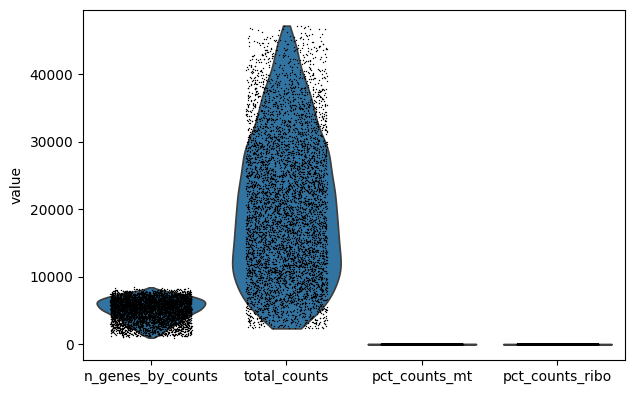

In [8]:
# --- 1. 基于总 UMI 计数（测序深度）过滤 Spot ---

sc.pp.filter_cells(adata, min_counts=min_counts)
sc.pp.filter_cells(adata, max_counts=max_counts)

# --- 2. 基于生物学指标过滤 Spot（自定义阈值）---

# 检查是否存在线粒体百分比指标（pct_counts_mt）
if 'pct_counts_mt' in adata.obs:
    # 过滤掉线粒体基因计数百分比（mt%）高于 25% 的 Spot。
    adata = adata[adata.obs['pct_counts_mt'] < 25].copy()
    
# 检查是否存在核糖体百分比指标（pct_counts_ribo）
if 'pct_counts_ribo' in adata.obs:
    # 过滤掉核糖体基因计数百分比（ribo%）高于 30% 的 Spot。
    adata = adata[adata.obs['pct_counts_ribo'] < 30].copy()

# --- 3. 过滤低表达基因 ---

# 过滤掉在少于 10 个 Spot（细胞）中表达的基因。
# 移除这些极少表达的基因可以显著降低数据维度，减少计算负担，并提高统计显著性
sc.pp.filter_genes(adata, min_counts=10)

# --- 4. 重新计算 QC 指标（用于验证）---

# 重新标记过滤后的基因列表中的线粒体和核糖体基因
adata.var["mt"]  = adata.var_names.str.startswith(("mt-","mt."))
adata.var["ribo"] = adata.var_names.str.match(r"^(Rps|Rpl)\d", na=False)

# 重新计算过滤后的 Spot 的各项 QC 统计指标
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt","ribo"], inplace=True)

# --- 5. 输出结果与可视化验证 ---

# 打印过滤后剩余的 Spot 和基因数量
print("Remaining spots:", adata.n_obs, "| genes:", adata.n_vars)

# 准备 QC 指标列表，确保这些指标列在 adata.obs 中存在
qc_keys = [k for k in ["n_genes_by_counts","total_counts","pct_counts_mt","pct_counts_ribo"] if k in adata.obs.columns]

# 绘制小提琴图，验证过滤效果（过滤后分布应更集中）
if adata.n_obs > 0 and qc_keys:
    # sc.pl.violin：绘制小提琴图，展示过滤后 QC 指标的分布情况
    # jitter=0.3：散点图中的点添加少量随机扰动
    # multi_panel=True：将多个小提琴图放在一个图中展示
    sc.pl.violin(adata, qc_keys, jitter=0.3)
else:
    # 如果过滤后没有 Spot 或 QC 关键指标缺失，则跳过绘图
    print("⚠️ Skipping violin plot: no spots or missing QC keys.")

## 3. 基础处理，均一化(normalize)

In [9]:
# 将原始的计数数据（通常存储在 adata.X 中）复制一份，保留原始数据，方便后续操作（如标准化、对数化）后进行比对
adata.layers['raw_counts'] = adata.X.copy()

# 进行总数归一化（Total-count normalization）。
sc.pp.normalize_total(adata)

# 对数据进行对数化转换（log-transformation，这一步有助于稳定数据的方差，使基因表达分布更接近正态
sc.pp.log1p(adata)

In [10]:
# 识别高度变异基因（Highly Variable Genes, HVGs）
# 这里我们使用 "pearson_residuals" 方法，并基于原始计数数据层（'raw_counts'）来识别 HVGs
# 选择前 3000 个高度变异基因
# subset=False 表示不直接在 AnnData 对象中筛选这些基因，而是将结果存储在 adata.var 中，以便后续查看和使用
sc.experimental.pp.highly_variable_genes(
    adata, 
    flavor="pearson_residuals",
    layer='raw_counts',
    n_top_genes=3000,
    subset=False,
    inplace=True,
)
# 查看识别出的高度变异基因的统计信息
print(adata.var['highly_variable'].value_counts())
# 仅保留高度变异基因，进行后续分析
adata=adata[:,adata.var['highly_variable']==True]

highly_variable
False    14311
True      3000
Name: count, dtype: int64


In [11]:
adata

View of AnnData object with n_obs × n_vars = 5591 × 3000
    obs: 'in_tissue', 'array_row', 'array_col', 'library_id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'n_counts'
    var: 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_counts', 'means', 'variances', 'residual_variances', 'highly_variable_rank', 'highly_variable'
    uns: 'spatial', 'log1p', 'hvg'
    obsm: 'spatial'
    layers: 'raw_counts'

In [12]:
# 数据缩放 (Scaling)
# 对数据（通常是经过 log1p 转换后的表达矩阵）进行 Z-score 标准化（或称特征缩放）
# 这一步计算每个基因的均值和标准差，并将数据转换为均值为 0、标准差为 1 的形式
# max_value=10: 这是一个关键参数。它会将标准化后的值限制在 -10 到 10 之间
# 目的：
#   1. 防止少数极高方差的基因（通常是高变基因）过度影响降维结果（如 PCA）。
#   2. 平衡不同基因在后续分析中的权重，防止方差大的基因主导结果。
sc.pp.scale(adata, max_value=10)

# 主成分分析 (Principal Component Analysis, PCA)
# 对经过缩放的数据执行线性降维。
#
# n_comps=50: 指定要计算的主成分 (PCs) 的数量为 50 个。
# 目的：
#   1. 提取数据中最大的变异来源（即主成分）。
#   2. 将数据从高维特征空间（基因数）投影到一个较低维度的空间（50个 PC），
#      从而大大减少后续计算的复杂度，并去除部分数据噪声。

# 结果：计算出的主成分会存储在 adata.obsm['X_pca'] 中，
#      用于后续的聚类、t-SNE/UMAP 可视化和差异表达分析等。
sc.pp.pca(adata, n_comps=50)

/home/puddddd/miniconda3/envs/scvi_env/lib/python3.10/site-packages/scanpy/preprocessing/_scale.py:309: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)
/home/puddddd/miniconda3/envs/scvi_env/lib/python3.10/functools.py:889: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


## 4. 聚类

In [13]:
# 计算邻域图 (Nearest Neighbors Graph)
# 构建一个基于spot之间相似度的图结构，它是后续聚类和非线性降维的基础。
#
# n_neighbors=30: 指定在图中，每个spot将连接到它最近的 30 个邻居spot。
#                 这个参数决定了局部和全局结构的平衡。
# use_rep='X_pca': 明确使用之前 PCA 降维的结果（存储在 adata.obsm['X_pca']）来计算距离。
#                  使用低维度的 PC 空间可以提高计算效率并减少噪声影响。
sc.pp.neighbors(adata, n_neighbors=30, use_rep='X_pca')

/home/puddddd/miniconda3/envs/scvi_env/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [14]:
# Leiden 聚类 (Clustering)
# 使用 Leiden 算法对上一步构建的邻域图进行社区检测（聚类）。
# 目的：将spot划分成不同的组或“簇 (Clusters)”，每个簇代表一种潜在的spot类型或状态。
#
# key_added="clusters": 将聚类的结果（即每个spot所属的簇的标签）存储在 adata.obs 
#                      中，列名为 "clusters"。
sc.tl.leiden(adata, key_added="clusters", resolution=0.8)

# t-SNE 降维 (Visualization)
# 执行 t-distributed Stochastic Neighbor Embedding (t-SNE) 非线性降维。
# 目的：生成spot的二维坐标，用于在图上直观地展示spot群体间的关系和差异。
#      t-SNE 擅长保留数据的局部结构（即相似spot在图上会靠得近）。
sc.tl.tsne(adata)

# UMAP 降维 (Visualization)
# 执行 Uniform Manifold Approximation and Projection (UMAP) 非线性降维。
# 目的：与 t-SNE 类似，生成用于可视化的二维坐标。
#      UMAP 通常运行速度更快，并且相比 t-SNE 更好地保留了数据的全局结构。
sc.tl.umap(adata)

/tmp/ipykernel_192414/2228180361.py:7: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(adata, key_added="clusters", resolution=0.8)


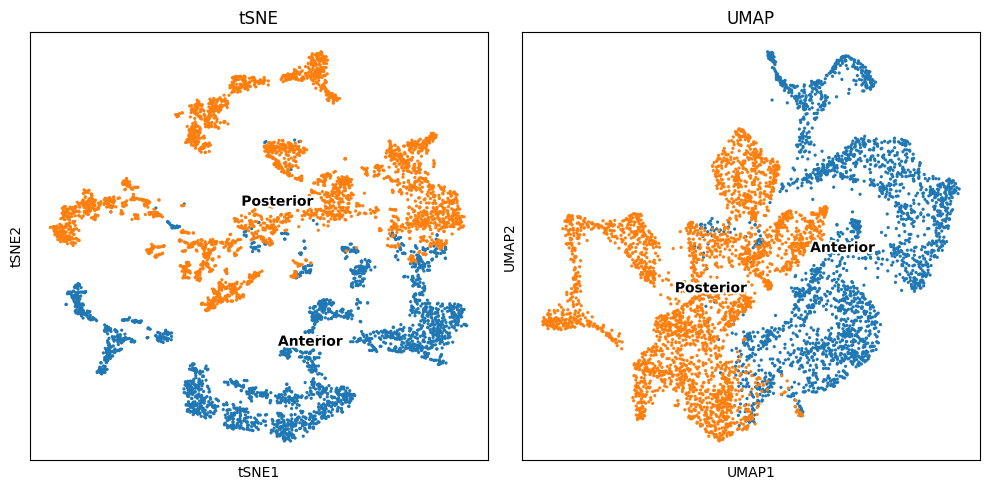

In [15]:
# 创建一个 1 行 2 列的 Matplotlib 画布，用于并排放置两个图。
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# 绘制左侧的 t-SNE 图。
# 'color="library_id"': 根据批次 ID (library_id) 给spot点上色。
# 'ax=axes[0]': 绘制到左侧的子图上。
p1 = sc.pl.tsne(adata, color="library_id", legend_loc="on data", show=False, legend_fontoutline=3, ax=axes[0]);
# 设置左图标题。
axes[0].set_title("tSNE")

# 绘制右侧的 UMAP 图。
# 'color="library_id"': 同样根据批次 ID 上色。
# 'ax=axes[1]': 绘制到右侧的子图上。
p2 = sc.pl.umap(adata, color="library_id", legend_loc="on data", show=False, legend_fontoutline=3, ax=axes[1]);
# 设置右图标题。
axes[1].set_title("UMAP")

# 自动调整子图间距，防止重叠。
plt.tight_layout()
# 显示最终的图像。
plt.show()

可以看出两个样本间批次效应非常明显

In [16]:
# 确保运行了这部分代码来设置全局颜色：
import matplotlib as mpl
import matplotlib.colors 
import matplotlib.cm as cm 

all_clusters = sorted(adata.obs['clusters'].unique())
n_clusters = len(all_clusters)

# 使用 gist_ncar 或其他大容量调色板
cmap = cm.get_cmap('gist_ncar', n_clusters) 
cluster_colors = [matplotlib.colors.to_hex(cmap(i)) for i in range(n_clusters)]

# 关键：将颜色分配给全局键
adata.uns['clusters_colors'] = cluster_colors

/tmp/ipykernel_192414/3462848146.py:10: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('gist_ncar', n_clusters)


/home/puddddd/miniconda3/envs/scvi_env/lib/python3.10/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]
/home/puddddd/miniconda3/envs/scvi_env/lib/python3.10/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]


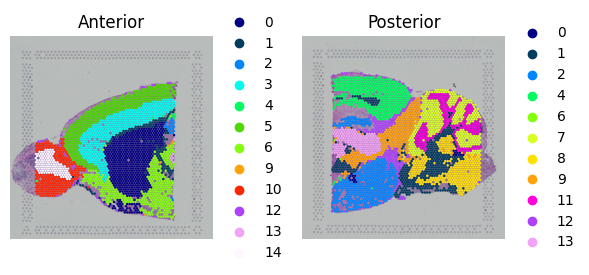

In [18]:
# 1. 创建一个 1 行 2 列的 Matplotlib 画布，用于并排放置两个空间图，总大小为 6x3 英寸。
fig, axes = plt.subplots(1, 2, figsize=(6, 3))

# 2. 使用 zip 循环遍历：
# x: Matplotlib 子图对象 (axes[0] 和 axes[1])。
# y: 排序后的空间样本 ID。
for x, y in zip(axes, sorted(adata.uns['spatial'].keys())):
    # 绘制空间图：
    sq.pl.spatial_scatter(
        # 筛选出当前循环的样本数据
        adata[adata.obs.library_id == y], 
        frameon=False,  # 不显示图表的边框。
        color="clusters",  # 根据 'clusters' 结果上色，它现在使用全局颜色。
        size=1.5,  # 设置空间点的大小。
        library_id=y,  # 指定要绘制的样本 ID（用于图像和坐标）。
        title=y,  # 设置子图标题为样本 ID。
        ax=x,  # 绘制到当前循环的子图对象上。
        figsize=(8,6),
        # 控制图例的位置：将图例放在右侧边缘，另一个图不显示图例。
        legend_loc="right margin"
    )

# 3. 调整子图之间的宽度
plt.tight_layout()

## 5. 不同的去批次方法

### 5.1 harmony去批次

Harmony 的核心目标是消除技术差异（批次效应），保留生物学差异。它致力于确保来自不同批次的同类型spot能够很好地混合在一起，而不同类型的spot（即使来自同一批次）仍然保持分离。

⚙️ 工作原理 (简单来说)
Harmony 的工作流程不是直接修改原始基因表达矩阵（adata.X），而是校正低维嵌入（通常是 PCA 降维后的坐标）。它采用迭代的方式进行批次校正：

1. 初始化：首先使用 PCA 得到初始低维坐标。

2 .迭代校正：

- 在每次迭代中，Harmony 运行聚类算法（例如 k-means），识别出潜在的聚类。

- 对于每个spot群，它会计算一个校正向量。这个向量会减小不同批次在该聚类内的差异。

- 它将这个校正向量应用到每个spot的坐标上，使来自不同批次的spot在这个群内更靠近。

3. 收敛：重复以上步骤，直到批次间的差异被充分消除，达到收敛状态。

✅ 主要优势
- 高效灵活：它对大规模数据集非常高效，并且可以轻松地同时整合多个批次（Covariates）。

- 保留生物学结构：由于它是在低维空间进行操作，并且是在识别了聚类之后进行局部校正，因此它被认为能够很好地保留数据原有的生物学变异。

- 广泛推荐：在许多空间（单细胞）数据整合方法的基准测试中，Harmony 表现出稳定的性能，被认为是进行批次校正的推荐方法之一。

![](http://biomamba.com:34080/free.download/file.back/biomamba/chenao/harmony.png)

In [19]:
# 导入 scanpy.external 模块，其中包含一些社区贡献的、非核心的工具。
import scanpy.external as sce 
# 导入 harmonypy 库，Harmony 算法的 Python 实现
# Harmony 是一种流行的批次效应校正方法
import harmonypy as hm 

# adata: 要处理的 AnnData 对象
# 'library_id': 指定 AnnData.obs 中包含批次信息（即需要校正的批次/实验 ID）的列名
# 结果：校正后的低维嵌入（如 PCA 结果）将存储在 adata.obsm['X_harmony'] 中，用于后续分析
sce.pp.harmony_integrate(adata, 'library_id')

2025-10-15 14:45:10,424 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2025-10-15 14:45:12,411 - harmonypy - INFO - sklearn.KMeans initialization complete.
2025-10-15 14:45:12,494 - harmonypy - INFO - Iteration 1 of 10
2025-10-15 14:45:13,537 - harmonypy - INFO - Iteration 2 of 10
2025-10-15 14:45:14,418 - harmonypy - INFO - Iteration 3 of 10
2025-10-15 14:45:15,318 - harmonypy - INFO - Iteration 4 of 10
2025-10-15 14:45:15,990 - harmonypy - INFO - Converged after 4 iterations


In [20]:
# 检查harmony去批次后的结果
adata

AnnData object with n_obs × n_vars = 5591 × 3000
    obs: 'in_tissue', 'array_row', 'array_col', 'library_id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'n_counts', 'clusters'
    var: 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_counts', 'means', 'variances', 'residual_variances', 'highly_variable_rank', 'highly_variable', 'mean', 'std'
    uns: 'spatial', 'log1p', 'hvg', 'pca', 'neighbors', 'clusters', 'tsne', 'umap', 'library_id_colors', 'clusters_colors'
    obsm: 'spatial', 'X_pca', 'X_tsne', 'X_umap', 'X_pca_harmony'
    varm: 'PCs'
    layers: 'raw_counts'
    obsp: 'distances', 'connectivities'

#### 重新聚类

In [21]:
# 使用harmony去批次后的结果进行后续分析
# use_rep='X_pca_harmony': 指定使用 Harmony 校正后的 PCA 结果进行
sc.pp.neighbors(adata, n_neighbors=30, use_rep='X_pca_harmony')
sc.tl.leiden(adata, key_added="cluster_hm")
sc.tl.tsne(adata,use_rep='X_pca_harmony')
sc.tl.umap(adata)

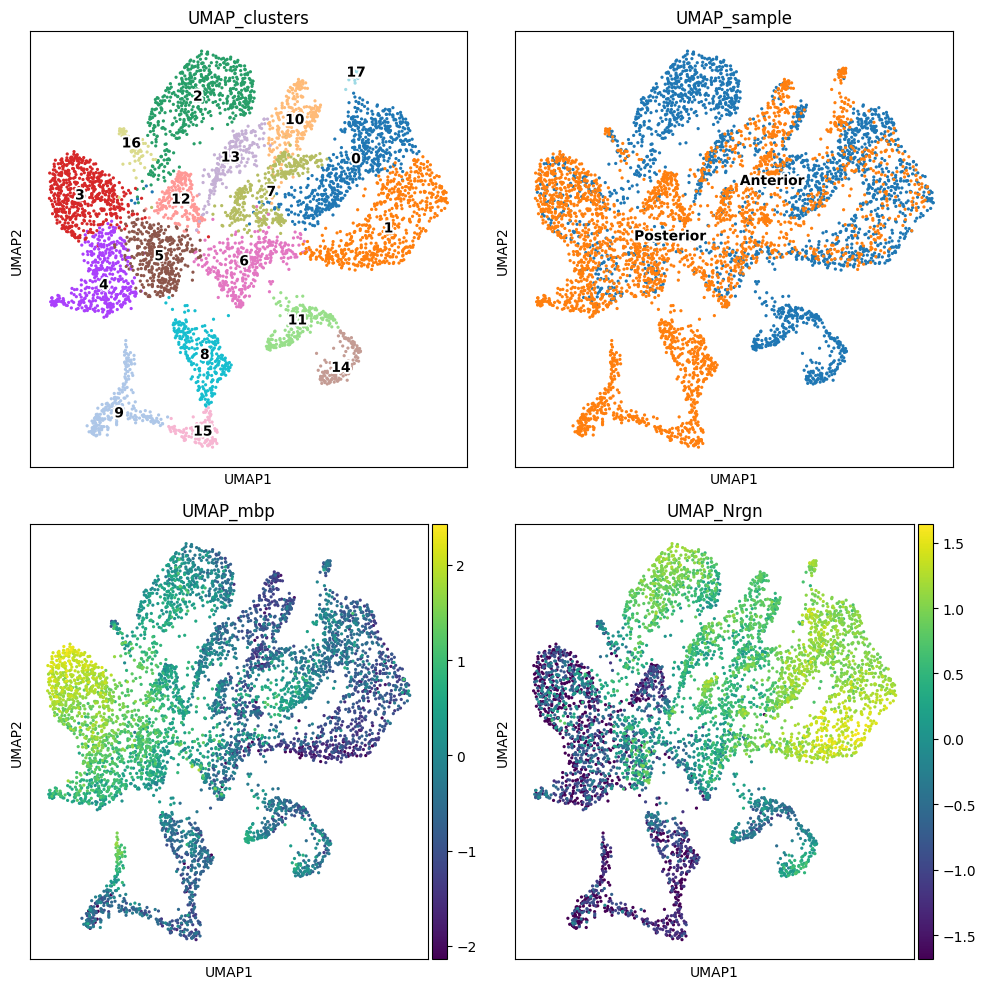

In [22]:
# 创建一个 2 行 2 列（共 4 个子图）的 Matplotlib 画布，总大小为 10x10 英寸。
fig, axes = plt.subplots(2, 2, figsize=(10, 10))
# 将 2x2 的二维数组 axes 展平为包含 4 个元素的长度为 4 的一维数组。
axes = axes.flatten()

# 绘制左上角的 UMAP 图 (axes[0])
# color="cluster_hm": 根据spot的聚类结果进行着色。
p1 = sc.pl.umap(adata, color="cluster_hm", legend_loc="on data", show=False, legend_fontoutline=3, ax=axes[0]);
# 设置标题。
axes[0].set_title("UMAP_clusters")

# 绘制右上角的 UMAP 图 (axes[1])
# color="library_id": 根据批次/样本 ID 进行着色 (用于评估批次效应)。
p2 = sc.pl.umap(adata, color="library_id", legend_loc="on data", show=False, legend_fontoutline=3, ax=axes[1]);
# 设置标题。
axes[1].set_title("UMAP_sample")

# 绘制左下角的 UMAP 图 (axes[2])
# color="Plp1": 根据基因 Plp1 的表达水平进行着色 (用于标记特定spot类型，如少突胶质细胞)。
p3 = sc.pl.umap(adata, color="Plp1", legend_loc="on data", show=False, legend_fontoutline=3, ax=axes[2]);
# 设置标题。
axes[2].set_title("UMAP_mbp") # 注意：标题可能是 Plp1 基因名或其代表的细胞类型。

# 绘制右下角的 UMAP 图 (axes[3])
# color="Nrgn": 根据基因 Nrgn 的表达水平进行着色 (用于标记特定细胞类型，如神经元)。
p4 = sc.pl.umap(adata, color="Nrgn", legend_loc="on data", show=False, legend_fontoutline=3, ax=axes[3]);
# 设置标题。
axes[3].set_title("UMAP_Nrgn")

# 自动调整子图间距，防止重叠。
plt.tight_layout()
# 显示最终的 2x2 图像。
plt.show()

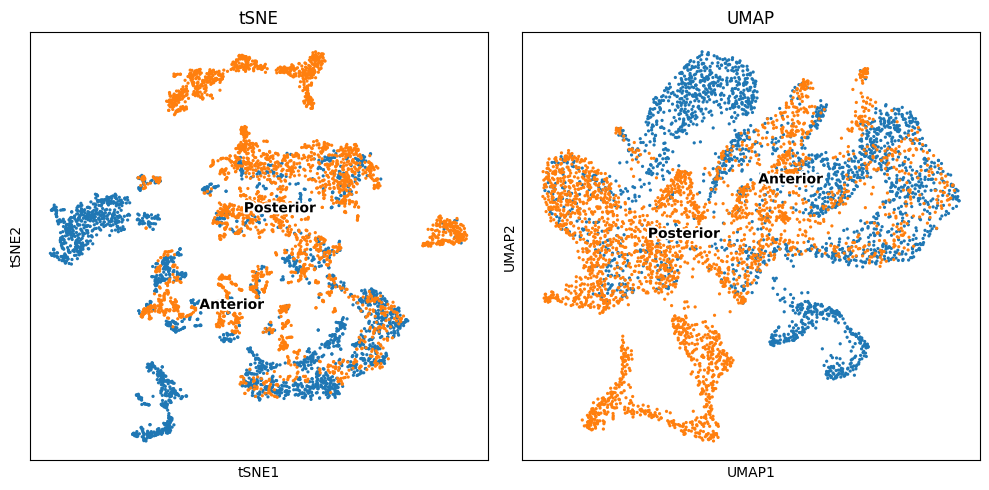

In [23]:
# 创建一个 1 行 2 列的 Matplotlib 画布，用于并排放置两个图。
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
# 绘制左侧的 t-SNE 图 (axes[0])。
# color="library_id": 根据批次/样本 ID (library_id) 给spot点上色。
# show=False: 暂时不显示，以便后续统一处理。
p1 = sc.pl.tsne(adata, color="library_id", legend_loc="on data", show=False, legend_fontoutline=3, ax=axes[0]);
# 设置左图标题。
axes[0].set_title("tSNE")

# 绘制右侧的 UMAP 图 (axes[1])。
# color="library_id": 同样根据批次 ID 上色。
p2 = sc.pl.umap(adata, color="library_id", legend_loc="on data", show=False, legend_fontoutline=3, ax=axes[1]);
# 设置右图标题。
axes[1].set_title("UMAP")

# 自动调整子图间距，防止重叠。
plt.tight_layout()
# 显示最终的图像。
plt.show()

可以看出harmony去批次后两个样本间的差异被较好地矫正

### 5.2 Scanorama

Scanorama可以识别和合并共享的spot类型之间的所有数据集和准确集成的数据的异构集合

- 特征选择：选择高变基因，减少噪声

- 低维表示：对每个数据集做 truncated SVD，每个spot用低维向量表示

- 寻找跨批次最近邻，在另一个数据集找到它的最近邻（Mutual Nearest Neighbors）

- 对每个 MNN 对计算 矢量差，生成 校正向量，把批次数据沿着这个向量平移

- 按照找到的 MNN 关系，把每个 batch 的表达矩阵平移到同一个低维空间


![](http://biomamba.com:34080/free.download/file.back/biomamba/chenao/scanorama.png)

In [24]:
import scanorama

# 获取 AnnData 对象 (adata) 中批次信息列 ('library_id') 的所有唯一类别（即所有批次 ID）
# .cat.categories: 获取分类数据的类别名称
# .tolist(): 将结果转换为 Python 列表
batch_cats = adata.obs['library_id'].cat.categories.tolist()

# 使用列表推导式 (List Comprehension) 将主 AnnData 对象分割成多个子 AnnData 对象列表
# 循环遍历每个批次 ID (b)
# adata[adata.obs['library_id'] == b].copy(): 筛选出当前批次 ID (b) 的所有spot，并创建一个新的副本
# 结果：adata_list 包含与 batch_cats 数量相同的、按批次分离的 AnnData 对象
adata_list = [adata[adata.obs['library_id'] == b].copy() for b in batch_cats]

In [25]:
# # adata_list: 存储着按 'library_id'（批次/样本 ID）分割后的多个独立的 AnnData 对象副本的列表
adata_list

[AnnData object with n_obs × n_vars = 2516 × 3000
     obs: 'in_tissue', 'array_row', 'array_col', 'library_id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'n_counts', 'clusters', 'cluster_hm'
     var: 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_counts', 'means', 'variances', 'residual_variances', 'highly_variable_rank', 'highly_variable', 'mean', 'std'
     uns: 'spatial', 'log1p', 'hvg', 'pca', 'neighbors', 'clusters', 'tsne', 'umap', 'library_id_colors', 'clusters_colors', 'cluster_hm', 'cluster_hm_colors'
     obsm: 'spatial', 'X_pca', 'X_tsne', 'X_umap', 'X_pca_harmony'
     varm: 'PCs'
     layers: 

In [26]:
# 使用 Scanorama 算法对之前分割的 AnnData 对象列表进行整合
# scanorama.integrate_scanpy(): Scanorama 在 Scanpy 中的接口函数
# adata_list: 包含按批次分割的多个 AnnData 对象的列表
# 目的：消除不同批次间的技术差异（批次效应），使同类型spot无论来自哪个批次都能聚集在一起
# 结果：整合后的低维嵌入（校正后的特征）会存储回原始的 adata.obsm 中，通常名为 'X_scanorama'
scanorama.integrate_scanpy(adata_list)

Found 3000 genes among all datasets
[[0.         0.44316375]
 [0.         0.        ]]
Processing datasets (0, 1)


In [27]:
# 在原始 adata 对象的 .obsm（观察值矩阵，用于存储降维或整合结果）中，创建一个名为 "X_scanorama" 的新矩阵
# np.zeros(): 初始化一个全零矩阵
# adata.shape[0]: 确保新矩阵的行数等于原始 adata 中的spot总数
# adata_list[0].obsm["X_scanorama"].shape[1]: 确保新矩阵的列数（即整合后的特征维度）与第一个批次的 Scanorama 结果的维度相同
adata.obsm["X_scanorama"] = np.zeros((adata.shape[0], adata_list[0].obsm["X_scanorama"].shape[1]))

# 循环合并结果：
# 遍历批次 ID 列表（batch_cats，即所有样本 ID），同时获取索引 i 和批次 ID b
for i, b in enumerate(batch_cats):
    # 根据当前批次 ID (b) 筛选出原始 adata 中对应的spot行
    # 将 adata_list 中第 i 个批次（已整合）的 Scanorama 结果，赋值给原始 adata 中对应的行
    adata.obsm["X_scanorama"][adata.obs['library_id'] == b] = adata_list[i].obsm["X_scanorama"]

# 输出 adata 对象，通常用于展示其当前状态和已添加的键。
adata

AnnData object with n_obs × n_vars = 5591 × 3000
    obs: 'in_tissue', 'array_row', 'array_col', 'library_id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'n_counts', 'clusters', 'cluster_hm'
    var: 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_counts', 'means', 'variances', 'residual_variances', 'highly_variable_rank', 'highly_variable', 'mean', 'std'
    uns: 'spatial', 'log1p', 'hvg', 'pca', 'neighbors', 'clusters', 'tsne', 'umap', 'library_id_colors', 'clusters_colors', 'cluster_hm', 'cluster_hm_colors'
    obsm: 'spatial', 'X_pca', 'X_tsne', 'X_umap', 'X_pca_harmony', 'X_scanorama'
    varm: 'PCs'
    

In [28]:
# 使用 scanorama 去批次后的结果进行后续分析
# use_rep='X_scanorama': 指定使用 Scanorama 校正后的结果进行
sc.pp.neighbors(adata, n_neighbors=30, use_rep='X_scanorama')
sc.tl.leiden(adata, key_added="cluster_scanorama")
sc.tl.tsne(adata,use_rep='X_scanorama')
sc.tl.umap(adata)

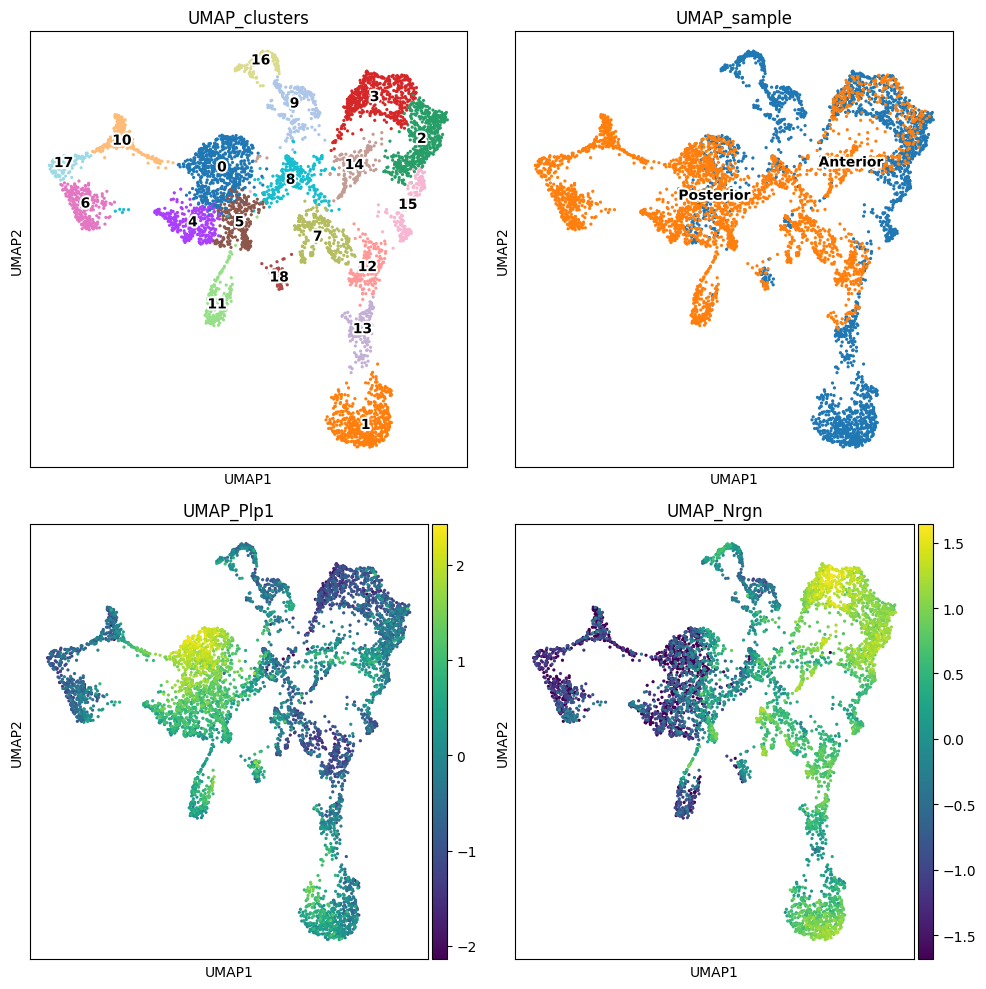

In [29]:
# 创建一个 2 行 2 列（共 4 个子图）的 Matplotlib 画布
fig, axes = plt.subplots(2, 2, figsize=(10, 10))
# 将 2x2 的子图数组展开成一维数组，方便循环和索引
axes = axes.flatten()

# 绘制左上角的 UMAP 图 (axes[0])
# color="cluster_scanorama": 根据最新的聚类结果进行着色（基于批次校正后的数据）
p1 = sc.pl.umap(adata, color="cluster_scanorama", legend_loc="on data", show=False, legend_fontoutline=3, ax=axes[0]);
# 设置标题为聚类结果
axes[0].set_title("UMAP_clusters")

# 绘制右上角的 UMAP 图 (axes[1])
# color="library_id": 根据批次/样本 ID 进行着色。用于最终检查批次是否成功混合
p2 = sc.pl.umap(adata, color="library_id", legend_loc="on data", show=False, legend_fontoutline=3, ax=axes[1]);
# 设置标题为样本 ID
axes[1].set_title("UMAP_sample")

# 绘制左下角的 UMAP 图 (axes[2])
# color="Plp1": 根据基因 Plp1 的表达水平上色（Plp1 是少突胶质细胞的标志基因）
p3 = sc.pl.umap(adata, color="Plp1", legend_loc="on data", show=False, legend_fontoutline=3, ax=axes[2]);
# 设置标题为基因 Plp1
axes[2].set_title("UMAP_Plp1")

# 绘制右下角的 UMAP 图 (axes[3])
# color="Nrgn": 根据基因 Nrgn 的表达水平上色（Nrgn 是神经元的标志基因）
p4 = sc.pl.umap(adata, color="Nrgn", legend_loc="on data", show=False, legend_fontoutline=3, ax=axes[3]);
# 设置标题为基因 Nrgn
axes[3].set_title("UMAP_Nrgn")

# 自动调整子图间距，防止标签和标题重叠
plt.tight_layout()
# 显示最终的 2x2 图像
plt.show()

Scanorama进行了一定程度的矫正，但矫正效果不如harmony

### 5.3 Combat矫正

ComBat（**Com**bating **Bat**ch Effects）是一种经典的批次效应校正方法，适用于消除多张**空间转录组切片/批次**之间 Spot 表达数据的技术差异。

核心原理

ComBat 基于 **经验贝叶斯（Empirical Bayes）** 框架，直接对基因表达矩阵进行调整：

1.  **输入数据**：将 AnnData 对象的主矩阵 `adata.X`（行是 Spot，列是基因）作为输入。
2.  **建模分析**：对每个基因，建立一个线性模型，将基因表达的变异分解为：
    * **目标生物学效应**（如组织区域、细胞类型）。
    * **需要消除的批次效应**（`library_id` 或 `slice_id`）。
3.  **参数估计**：使用经验贝叶斯方法估计批次效应的均值（加性效应）和方差（乘性效应）。
4.  **直接矫正**：将估计出的批次效应从 Spot 的表达值中去除。



In [85]:
# adata_combat: 创建原始 AnnData 对象 (adata) 的一个完整副本
# 目的：为下一步使用 ComBat 算法进行批次效应校正准备一个独立的数据集
#      避免修改原始的 adata 对象，从而保持数据的完整性
adata_combat = adata.copy()

In [86]:
# 使用 ComBat 算法进行批次效应校正
# adata_combat: 输入数据对象，通常是原始数据的副本
# key='library_id': 关键！指定 adata_combat.obs 中包含批次信息（即需要校正的批次/实验 ID）的列名
# 目的：利用线性模型，对每个基因进行均值和方差的调整，从而消除批次间的技术差异
# 结果：校正后的表达数据将直接替换 adata_combat.X 中的原始数据
sc.pp.combat(adata_combat, key='library_id')

/home/puddddd/miniconda3/envs/scvi_env/lib/python3.10/site-packages/scanpy/preprocessing/_combat.py:343: RuntimeWarning: divide by zero encountered in divide
  (abs(g_new - g_old) / g_old).max(), (abs(d_new - d_old) / d_old).max()


In [87]:
# 使用 ComBat 去批次后的结果进行后续分析
# 由于 ComBat 校正直接修改了 adata_combat.X，因此我们可以直接使用它进行后续分析
# 这里我们再次执行 PCA、邻域图计算、聚类和非线性降维
sc.pp.pca(adata_combat, n_comps=50)
sc.pp.neighbors(adata_combat, n_neighbors=30, use_rep='X_pca')
sc.tl.leiden(adata_combat, key_added="cluster_combat")
sc.tl.tsne(adata_combat,use_rep='X_pca')
sc.tl.umap(adata_combat)

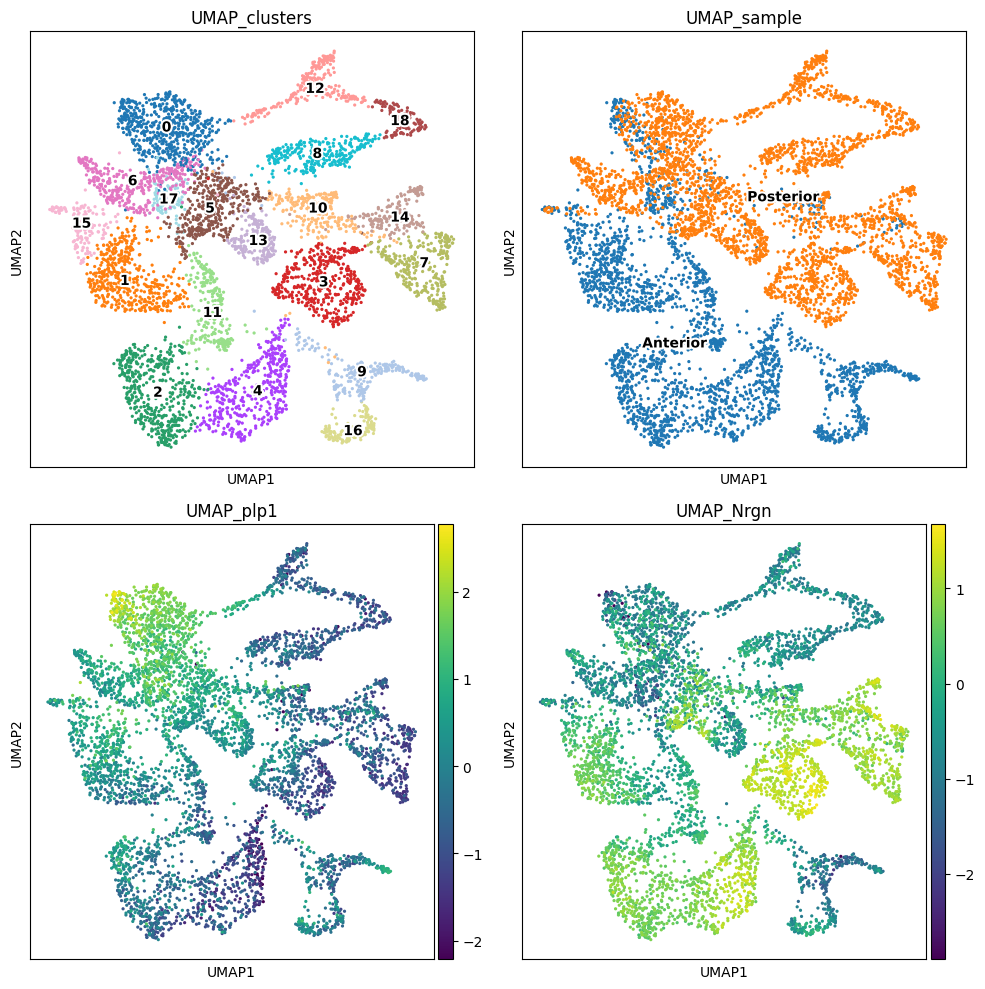

In [88]:
# 创建一个 2 行 2 列（共 4 个子图）的 Matplotlib 画布
fig, axes = plt.subplots(2, 2, figsize=(10, 10))
# 将 2x2 的子图数组展开成一维数组 (axes[0]到axes[3])，方便操作
axes = axes.flatten()

# 绘制左上角的 UMAP 图 (axes[0])
# 注意：使用 adata_combat 数据对象
# color="cluster_combat": 根据spot聚类结果上色
p1 = sc.pl.umap(adata_combat, color="cluster_combat", legend_loc="on data", show=False, legend_fontoutline=3, ax=axes[0]);
# 设置标题。
axes[0].set_title("UMAP_clusters")

# 绘制右上角的 UMAP 图 (axes[1])
# color="library_id": 根据批次 ID 上色。用于检查 ComBat 校正后的批次混合情况
p2 = sc.pl.umap(adata_combat, color="library_id", legend_loc="on data", show=False, legend_fontoutline=3, ax=axes[1]);
# 设置标题
axes[1].set_title("UMAP_sample")

# 绘制左下角的 UMAP 图 (axes[2])
# color="Plp1": 根据基因 Plp1 的表达水平上色（细胞类型标志基因）
p3 = sc.pl.umap(adata_combat, color="Plp1", legend_loc="on data", show=False, legend_fontoutline=3, ax=axes[2]);
# 设置标题。
axes[2].set_title("UMAP_plp1")

# 绘制右下角的 UMAP 图 (axes[3])
# color="Nrgn": 根据基因 Nrgn 的表达水平上色（细胞类型标志基因）
p4 = sc.pl.umap(adata_combat, color="Nrgn", legend_loc="on data", show=False, legend_fontoutline=3, ax=axes[3]);
# 设置标题。
axes[3].set_title("UMAP_Nrgn")

# 自动调整子图间距，防止重叠
plt.tight_layout()
# 显示最终的 2x2 图像
plt.show()

Combat 整合效果很一般

---

### 5.4 BBKNN矫正

**BBKNN**（**B**atch **B**alanced **K** **N**earest **N**eighbors，批次平衡 K 近邻）是一种专门为**快速**解决空间（单细胞）数据批次效应而设计的**基于图**的整合方法。

它不修改基因表达矩阵或低维嵌入，而是**直接修改细胞间的相似性网络（邻域图）**。

核心原理：图结构矫正

BBKNN 的矫正发生在构建 k-近邻图 (kNN Graph) 的步骤：

1.  **独立寻找邻居**：对于数据中的每一个 Spot（细胞），BBKNN 不是在整个数据集中寻找最近的 $k$ 个邻居，而是**分别在每一个批次内**寻找 $k$ 个邻居。
2.  **强制跨批次连接**：它将这些**批次内**找到的邻居列表合并起来，构建最终的邻域图。这意味着，即使两个 Spot 在总体上距离较远，但只要它们在各自的批次内是相似的，它们就会被连接起来。
3.  **平衡网络**：通过这种方式，BBKNN 确保了每个 Spot 的邻居网络在不同批次之间是**平衡的**，从而有效地“桥接”了不同批次间的同类型 Spot。

在空间转录组中的表现

| 方面 | 描述 |
| :--- | :--- |
| **矫正对象** | **仅修改邻域图（kNN Graph）**。原始基因表达矩阵 (`adata.X`) 和低维嵌入（如 PCA，`adata.obsm['X_pca']`）保持不变。 |
| **下游影响** | **所有依赖于邻域图**的下游分析（如 UMAP/t-SNE 可视化、Leiden/Louvain 聚类、轨迹推断）都将使用批次校正后的图结构，从而实现批次整合。 |
| **优点** | **极速高效**：由于算法设计和默认使用近似近邻搜索，BBKNN 速度非常快，尤其适合大规模数据集。**保留原始表达**：不修改表达矩阵，适用于后续需要原始数据的基因水平分析。 |
| **局限性** | **非空间感知**：与 ComBat 类似，它是一个**非空间感知**的方法，没有利用 Spot 的物理位置信息来辅助矫正。**仅限图相关分析**：校正效果局限于依赖 kNN 图的步骤。 |
| **应用场景** | 作为快速评估批次整合效果的首选工具。当主要目标是聚类和可视化时，BBKNN 是一个高效且强大的选择。 |

In [34]:
# 复制原始 AnnData 对象，为 BBKNN 批次校正做准备
# 避免修改原始的 adata 对象，从而保持数据的完整性
adata_BBKNN = adata.copy()

In [35]:
import bbknn

# 使用 BBKNN (Batch Balanced KNN) 算法进行批次效应校正
# adata_BBKNN: 输入的 AnnData 对象，通常是原始数据的副本
# batch_key='library_id': 关键！指定 adata_BBKNN.obs 中包含批次信息（即需要校正的批次/实验 ID）的列名
# 目的：在构建邻域图时，确保每个spot的邻居来自不同批次，从而有效消除批次效应
# 结果：校正后的邻域图将存储在 adata_BBKNN.uns 和 adata_BBKNN.obsm 中，用于后续的聚类和降维分析
sc.external.pp.bbknn(adata_BBKNN, batch_key='library_id')

# 使用 BBKNN 去批次后的结果进行后续分析
# 由于 BBKNN 校正直接修改了邻域图，因此我们可以直接使用它进行后续分析
# 这里我们再次执行聚类和非线性降维
sc.tl.leiden(adata_BBKNN, key_added="cluster_bbknn")
sc.tl.umap(adata_BBKNN)

In [38]:
key_added = 'X_BBKNN'
adata_BBKNN.obsm[f'{key_added}_umap'] = adata_BBKNN.obsm['X_umap'].copy()
adata_BBKNN

AnnData object with n_obs × n_vars = 5591 × 3000
    obs: 'in_tissue', 'array_row', 'array_col', 'library_id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'n_counts', 'clusters', 'cluster_hm', 'cluster_scanorama', 'cluster_bbknn'
    var: 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_counts', 'means', 'variances', 'residual_variances', 'highly_variable_rank', 'highly_variable', 'mean', 'std'
    uns: 'spatial', 'log1p', 'hvg', 'pca', 'neighbors', 'clusters', 'tsne', 'umap', 'library_id_colors', 'clusters_colors', 'cluster_hm', 'cluster_hm_colors', 'cluster_scanorama', 'cluster_scanorama_colors', 'cluster_bbkn

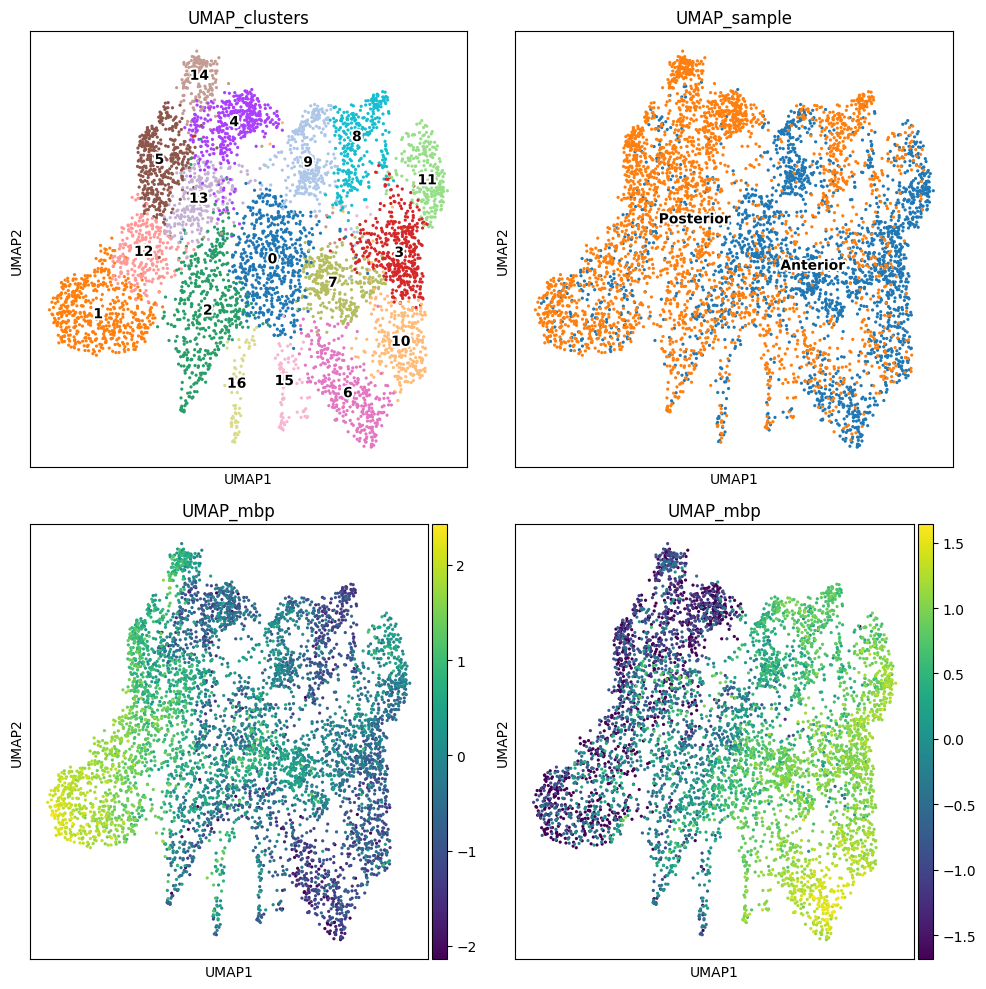

In [39]:
# 创建一个 2 行 2 列（共 4 个子图）的 Matplotlib 画布。
fig, axes = plt.subplots(2, 2, figsize=(10, 10))
# 将 2x2 的子图数组展开成一维数组 (axes[0]到axes[3])，方便索引。
axes = axes.flatten()

# 绘制左上角的 UMAP 图 (axes[0])。
# 注意：使用 adata_BBKNN 数据对象。
# color="Cluster": 根据细胞聚类结果上色（基于 BBKNN 优化的邻域图）。
p1 = sc.pl.umap(adata_BBKNN, color="cluster_bbknn", legend_loc="on data", show=False, legend_fontoutline=3, ax=axes[0]);
# 设置标题为聚类结果。
axes[0].set_title("UMAP_clusters")

# 绘制右上角的 UMAP 图 (axes[1])。
# color="library_id": 根据批次 ID 上色。用于检查 BBKNN 校正后的批次混合情况。
p2 = sc.pl.umap(adata_BBKNN, color="library_id", legend_loc="on data", show=False, legend_fontoutline=3, ax=axes[1]);
# 设置标题为样本 ID。
axes[1].set_title("UMAP_sample")

# 绘制左下角的 UMAP 图 (axes[2])。
# color="Plp1": 根据基因 Plp1 的表达水平上色（少突胶质细胞的标志基因）。
p3 = sc.pl.umap(adata_BBKNN, color="Plp1", legend_loc="on data", show=False, legend_fontoutline=3, ax=axes[2]);
# 设置标题。
axes[2].set_title("UMAP_mbp")

# 绘制右下角的 UMAP 图 (axes[3])。
# color="Nrgn": 根据基因 Nrgn 的表达水平上色（神经元的标志基因）。
p4 = sc.pl.umap(adata_BBKNN, color="Nrgn", legend_loc="on data", show=False, legend_fontoutline=3, ax=axes[3]);
# 设置标题。
axes[3].set_title("UMAP_mbp")

# 自动调整子图间距，防止重叠。
plt.tight_layout()
# 显示最终的 2x2 图像。
plt.show()

BBKNN的整合效果还不错，但是影响了不同细胞的聚类效果

### 5.5 深度学习模型

#### （1）基于变分自编码器的模型 scvi

**scVI** 是一个用于单细胞和空间组学数据的 **深度概率模型（Deep Probabilistic Model）** 框架。它利用 **变分自动编码器 (Variational Autoencoder, VAE)** 的强大能力，对单细胞表达数据进行建模、降噪和整合。

scVI 是整个 **scvi-tools** 库的核心模型之一，该库是基于 PyTorch 构建的，能够高效处理大规模单细胞数据集。

核心目标与原理

| 方面 | 描述 |
| :--- | :--- |
| **基础模型** | scVI 假设每个细胞的基因表达数据是从一个低维度的**潜在空间（Latent Space）**中生成的。这个潜在空间捕获了细胞的真实生物学状态。 |
| **数据生成** | 模型将高维的计数数据（`adata.X`）视为一个概率分布（通常是**负二项分布**），通过 VAE 学习将数据映射到潜在空间，并同时建模和消除技术因素（如测序深度、Dropouts 和**批次效应**）。 |
| **批次校正** | scVI 将批次信息作为一个**协变量 (Covariate)** 纳入模型。在潜在空间中，它会学习一个与批次无关的表示，从而有效地将来自不同批次的同类型细胞拉近。 |

scVI 的主要优势

1.  **全局整合和去噪**：scVI 不仅校正批次效应，同时还在潜在空间中实现了数据**归一化、去噪和缺失值填补 (Imputation)**，提高了数据质量。
2.  **可扩展性 (Scalability)**：基于 PyTorch 和 VAE 架构，scVI 能够利用 GPU 加速，非常高效地处理超过百万细胞的超大规模数据集。
3.  **多功能性**：scVI 框架支持多种下游任务：
    * **降维**：生成高质量的低维嵌入 (`X_scVI`) 用于可视化和聚类。
    * **差异表达分析**：基于概率模型进行更稳健的差异基因检测。
    * **迁移学习 (scArches)**：将新数据映射到预先训练好的单细胞图谱中，实现快速注释和整合。

与传统方法的区别

| 方法 | 操作空间 | 批次效应处理方式 |
| :--- | :--- | :--- |
| **ComBat** | 原始基因表达矩阵 (`adata.X`) | 线性模型，直接修正每个基因的表达均值和方差。 |
| **Harmony** | PCA 低维嵌入 (`X_pca`) | 迭代聚类，局部调整嵌入坐标。 |
| **scVI** | 学习到的潜在空间 (`X_scVI`) | 深度学习 VAE，通过概率模型将批次信息作为协变量去除。 |

**总结：** scVI 代表了单细胞数据分析的先进趋势，它将复杂的统计建模、深度学习的强大非线性建模能力和高效的计算性能结合起来，提供了一个全面的数据整合与分析解决方案。

![](http://biomamba.com:34080/free.download/file.back/biomamba/chenao/scvi.png)

In [40]:
# 导入 scvi-tools 库
# 它是用于单细胞和空间转录组数据的深度学习/概率模型框架，常用于批次校正、去噪和数据整合。
import scvi

# 导入 scib_metrics.benchmark 中的 Benchmarker 类
# scib (Single-Cell Integration Benchmark) 库用于系统地评估和比较不同的数据整合方法。
# Benchmarker 类是执行这些性能评估的核心工具。
from scib_metrics.benchmark import Benchmarker

In [68]:
# 本章内容我们会涉及到的GPU调用与计算
# 检查一下目前的GPU设备是否可用

# 检查 CUDA 是否可用
if not torch.cuda.is_available():
    print("🚨 警告：CUDA 当前不可用。PyTorch 无法识别任何 GPU。")
    print("请检查：1. NVIDIA 驱动；2. CUDA Toolkit 安装；3. PyTorch 是否为 GPU 版本。")
else:
    # 获取可用的 GPU 数量
    num_gpus = torch.cuda.device_count()
    print(f"✅ CUDA 环境已激活。系统共识别到 {num_gpus} 个 GPU 设备。\n")
    
    # 遍历并打印每个设备的信息
    for i in range(num_gpus):
        device_name = torch.cuda.get_device_name(i)
        
        print(f"--- 设备 {i} ---")
        print(f"ID (用于代码): cuda:{i}")
        print(f"型号名称: {device_name}")
        
    # 打印默认设备
    print(f"\n默认计算设备：cuda:{torch.cuda.current_device()}")

✅ CUDA 环境已激活。系统共识别到 1 个 GPU 设备。

--- 设备 0 ---
ID (用于代码): cuda:0
型号名称: NVIDIA GeForce RTX 3080

默认计算设备：cuda:0


In [58]:
# 复制原始 AnnData 对象，为 scVI 批次校正做准备
# 避免修改原始的 adata 对象，从而保持数据的完整性
adata_scvi = adata.copy()

In [61]:
# 设置 AnnData 对象以供 scVI 使用
# layer="raw_counts": 指定用于模型训练的原始计数数据层
# batch_key="library_id": 关键！指定 AnnData.obs 中包含批次信息（即需要校正的批次/实验 ID）的列名
# 目的：配置 AnnData 对象，使其符合 scVI 模型的输入要求
# 结果：scvi 会在后台处理数据，并为后续的模型训练和批次校正做好准备
scvi.model.SCVI.setup_anndata(adata_scvi, layer="raw_counts", batch_key="library_id")

In [62]:
# 初始化并训练 scVI 模型
# adata_scvi: 预处理并配置好的 AnnData 对象
# n_layers=2: 指定变分自编码器 (VAE) 的隐藏层数为 2 层
# n_latent=30: 指定潜在空间的维度为 30
# gene_likelihood="nb": 指定基因表达数据的似然分布为负二项分布 (Negative Binomial)，适用于计数数据
# 目的：通过深度生成模型学习数据的潜在表示，同时校正批次效应
# 结果：训练完成后，模型会存储在 vae 变量中，可用于生成校正后的嵌入和进行下游分析
model = scvi.model.SCVI(adata_scvi, n_layers=2, n_latent=30, gene_likelihood="nb")
model.train()

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/home/puddddd/miniconda3/envs/scvi_env/lib/python3.10/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:433: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=19` in the `DataLoader` to improve performance.


Epoch 400/400: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████| 400/400 [03:52<00:00,  1.72it/s, v_num=1, train_loss_step=2.93e+3, train_loss_epoch=2.9e+3]

`Trainer.fit` stopped: `max_epochs=400` reached.


Epoch 400/400: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████| 400/400 [03:52<00:00,  1.72it/s, v_num=1, train_loss_step=2.93e+3, train_loss_epoch=2.9e+3]


In [63]:
# 使用训练好的 scVI 模型生成批次校正后的潜在表示 (Latent Representation)
# vae.get_latent_representation(): 从训练好的 VAE 模型中提取潜在空间表示
# 结果：将生成的潜在表示存储在 adata.scvi.obsm["X_scVI"] 中
#      以便后续的聚类、降维和可视化分析
adata_scvi.obsm["X_scVI"] = model.get_latent_representation()

In [65]:
# 运行邻域图和聚类
sc.pp.neighbors(adata_scvi, use_rep="X_scVI")
sc.tl.umap(adata_scvi)
sc.tl.leiden(adata_scvi)

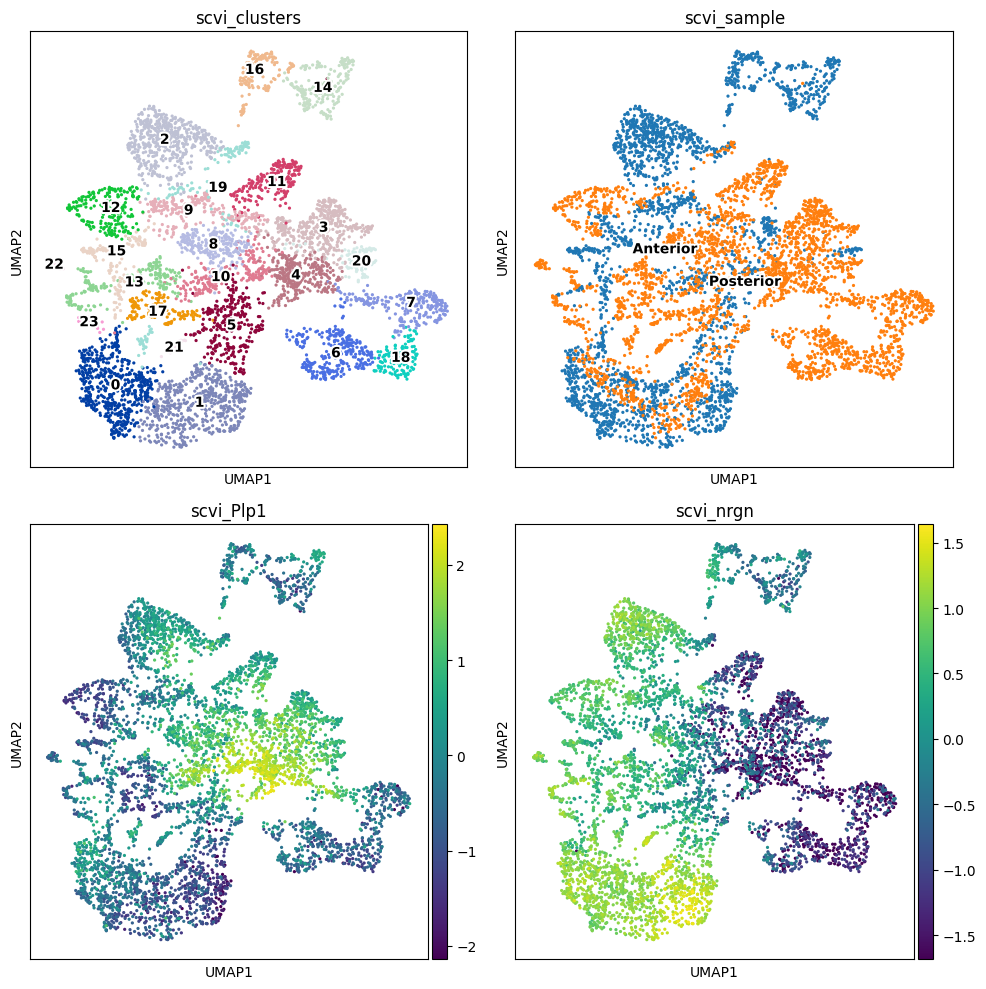

In [66]:
# 创建一个 2 行 2 列（共 4 个子图）的 Matplotlib 画布
fig, axes = plt.subplots(2, 2, figsize=(10, 10))
# 将 2x2 的子图数组展开成一维数组 (axes[0]到axes[3])，方便索引
axes = axes.flatten()

# 绘制左上角图 (axes[0])
# basis="X_scVI": 关键！使用 scVI 整合后（校正批次效应后）的低维嵌入作为绘图坐标
# color="cluster": 根据细胞聚类结果上色
p1 = sc.pl.umap(adata_scvi, color="leiden", legend_loc="on data", show=False, legend_fontoutline=3, ax=axes[0]);
# 设置标题
axes[0].set_title("scvi_clusters")

# 绘制右上角图 (axes[1])
# basis="X_scVI": 使用 scVI 嵌入
# color="library_id": 根据批次 ID 上色。用于检查 scVI 校正后的批次混合情况
p2 = sc.pl.umap(adata_scvi, color="library_id", legend_loc="on data", show=False, legend_fontoutline=3, ax=axes[1]);
# 设置标题
axes[1].set_title("scvi_sample")

# 绘制左下角图 (axes[2])
# basis="X_scVI": 使用 scVI 嵌入
# color="Plp1": 根据基因 Plp1 的表达水平上色（细胞类型标志基因）
p3 = sc.pl.umap(adata_scvi, color="Plp1", legend_loc="on data", show=False, legend_fontoutline=3, ax=axes[2]);
# 设置标题
axes[2].set_title("scvi_Plp1")

# 绘制右下角图 (axes[3])
# basis="X_scVI": 使用 scVI 嵌入
# color="Nrgn": 根据基因 Nrgn 的表达水平上色（细胞类型标志基因）
p4 = sc.pl.umap(adata_scvi, color="Nrgn", legend_loc="on data", show=False, legend_fontoutline=3, ax=axes[3]);
# 设置标题
axes[3].set_title("scvi_nrgn")

# 自动调整子图间距，防止重叠
plt.tight_layout()
# 显示最终的 2x2 图像
plt.show()

与线性嵌入的模型整合方法类似，scVI也取得了比较好的批次效应校正结果

---

#### （2）GraphST

**GraphST**（**Graph S**elf-supervised **T**ransformers）是一种基于 **图神经网络 (Graph Neural Network, GNN)** 的方法，专为解决多切片**空间转录组 (Spatial Transcriptomics, ST) 数据的整合、聚类和批次效应校正**而设计。

与 ComBat 和 Harmony 等非空间感知方法不同，GraphST 的核心优势在于它能够**同时利用基因表达信息和 Spot 的空间位置信息**进行整合。

核心目标与原理

| 方面 | 描述 |
| :--- | :--- |
| **整合目标** | 在整合多个空间切片（批次）时，同时实现：<br>1. **消除批次效应**（技术差异）。<br>2. **保留空间结构**（生物学差异）。 |
| **空间图构建** | GraphST 首先将每个空间切片建模为一个**图 (Graph)**，其中每个 **Spot** 是一个**节点 (Node)**，**空间上相邻**的 Spot 之间存在**边 (Edge)**。 |
| **GNN 特征学习** | 它使用 **图神经网络 (GNN)** 来学习 Spot 的低维嵌入。GNN 的特性确保了每个 Spot 的最终嵌入不仅基于其自身的基因表达，还**平滑地整合了周围邻居 Spot 的信息**（即空间上下文）。 |
| **整合机制** | 通过这种**空间感知**的特征学习，来自不同批次的 Spot，如果它们在空间上属于相似的组织结构，其潜在嵌入会被拉近。这有效地实现了**批次校正**，同时**保留了组织结构**。 |
| **自监督对比学习** | GraphST 进一步使用 **自监督对比学习** 机制，通过最小化空间相邻 Spot 的嵌入距离（正样本对）和最大化非相邻 Spot 的嵌入距离（负样本对），来学习更具辨别力的 Spot 表示。 |

GraphST 的主要优势

1.  **空间感知整合**：这是与传统批次校正方法（如 ComBat、Harmony）最大的区别。GraphST 能够利用 Spot 间的空间依赖性来指导整合，防止组织学上相似的区域被错误地分开。
2.  **多功能一体**：它不仅可以用于**多样本整合和批次校正**，还能用于**空间聚类**（识别空间域）和**细胞类型解卷积 (Deconvolution)** 等多种任务。
3.  **高性能**：在识别精细组织结构和跨样本整合方面，GraphST 在多个基准测试中表现优于许多现有的空间分析和整合方法。

GraphST 代表了空间转录组数据整合的**下一代方法**，它通过引入 **图神经网络**，将空间信息从一个约束条件提升为**核心的计算特征**，从而在消除批次效应的同时，更忠实地保留了组织微环境的生物学结构。

![](http://biomamba.com:34080/free.download/file.back/biomamba/chenao/graphST.png)

In [67]:
# 导入 scikit-learn (sklearn) 库中的 metrics 模块。
# 用于评估机器学习模型（例如聚类或分类）性能的各种指标（如 ARI, NMI, Silhouette Score 等）
from sklearn import metrics

# 导入 Python 标准库中的 multiprocessing 模块，并将其命名为 mp
# 用于创建和管理进程，实现并行计算，以加速处理大规模数据集（例如多核 CPU 任务）
import multiprocessing as mp

# 导入 GraphST 库中的 GraphST 类
# GraphST (Graph Self-supervised Transformers) 是一个专门用于空间转录组 (ST) 数据整合和分析的模型，利用图神经网络和自监督学习
from GraphST import GraphST

# 导入 PyTorch 库
# 这是一个流行的深度学习框架，GraphST 依赖于它进行模型构建、训练和 GPU 加速计算
import torch

/home/puddddd/miniconda3/envs/scvi_env/lib/python3.10/site-packages/GraphST/preprocess.py:10: DeprecationWarning: Please import `csc_matrix` from the `scipy.sparse` namespace; the `scipy.sparse.csc` namespace is deprecated and will be removed in SciPy 2.0.0.
  from scipy.sparse.csc import csc_matrix
/home/puddddd/miniconda3/envs/scvi_env/lib/python3.10/site-packages/GraphST/preprocess.py:11: DeprecationWarning: Please import `csr_matrix` from the `scipy.sparse` namespace; the `scipy.sparse.csr` namespace is deprecated and will be removed in SciPy 2.0.0.
  from scipy.sparse.csr import csr_matrix
/home/puddddd/miniconda3/envs/scvi_env/lib/python3.10/site-packages/GraphST/GraphST.py:10: DeprecationWarning: Please import `csc_matrix` from the `scipy.sparse` namespace; the `scipy.sparse.csc` namespace is deprecated and will be removed in SciPy 2.0.0.
  from scipy.sparse.csc import csc_matrix
/home/puddddd/miniconda3/envs/scvi_env/lib/python3.10/site-packages/GraphST/GraphST.py:11: Deprecati

In [71]:
# 初始化 GraphST 模型
# adata: 输入的 AnnData 对象，包含预处理后的空间转录组数据
# device=device: 指定计算设备（GPU 或 CPU），以利用硬件加速
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
# random_seed=50: 设置随机种子以确保结果的可重复性  
model = GraphST.GraphST(adata, device=device, random_seed=50)

In [72]:
# 训练 GraphST 模型
# 结果：训练完成后，校正和整合后的数据将存储在 model.adata_gt 中
#      该对象可用于后续的聚类、降维和可视化分析
adata_gt = model.train()

Begin to train ST data...


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 600/600 [00:15<00:00, 37.59it/s]


Optimization finished for ST data!


In [73]:
adata_gt

AnnData object with n_obs × n_vars = 5591 × 3000
    obs: 'in_tissue', 'array_row', 'array_col', 'library_id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'n_counts', 'clusters', 'cluster_hm', 'cluster_scanorama'
    var: 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_counts', 'means', 'variances', 'residual_variances', 'highly_variable_rank', 'highly_variable', 'mean', 'std'
    uns: 'spatial', 'log1p', 'hvg', 'pca', 'neighbors', 'clusters', 'tsne', 'umap', 'library_id_colors', 'clusters_colors', 'cluster_hm', 'cluster_hm_colors', 'cluster_scanorama', 'cluster_scanorama_colors'
    obsm: 'spatial', 'X_pca', '

In [74]:
# 使用 GraphST 去批次后的结果进行后续分析
# use_rep='emb': 指定使用 GraphST 模型生成的嵌入结果进行邻域图计算
# 结果：计算出的邻域图将存储在 adata_gt.uns 和 adata_gt.obsm 中，用于后续的聚类和降维分析
sc.pp.neighbors(adata_gt, n_neighbors=15, use_rep='emb')

In [76]:
# 基于 GraphST 嵌入结果进行聚类分析
sc.tl.umap(adata_gt)
sc.tl.leiden(adata_gt)

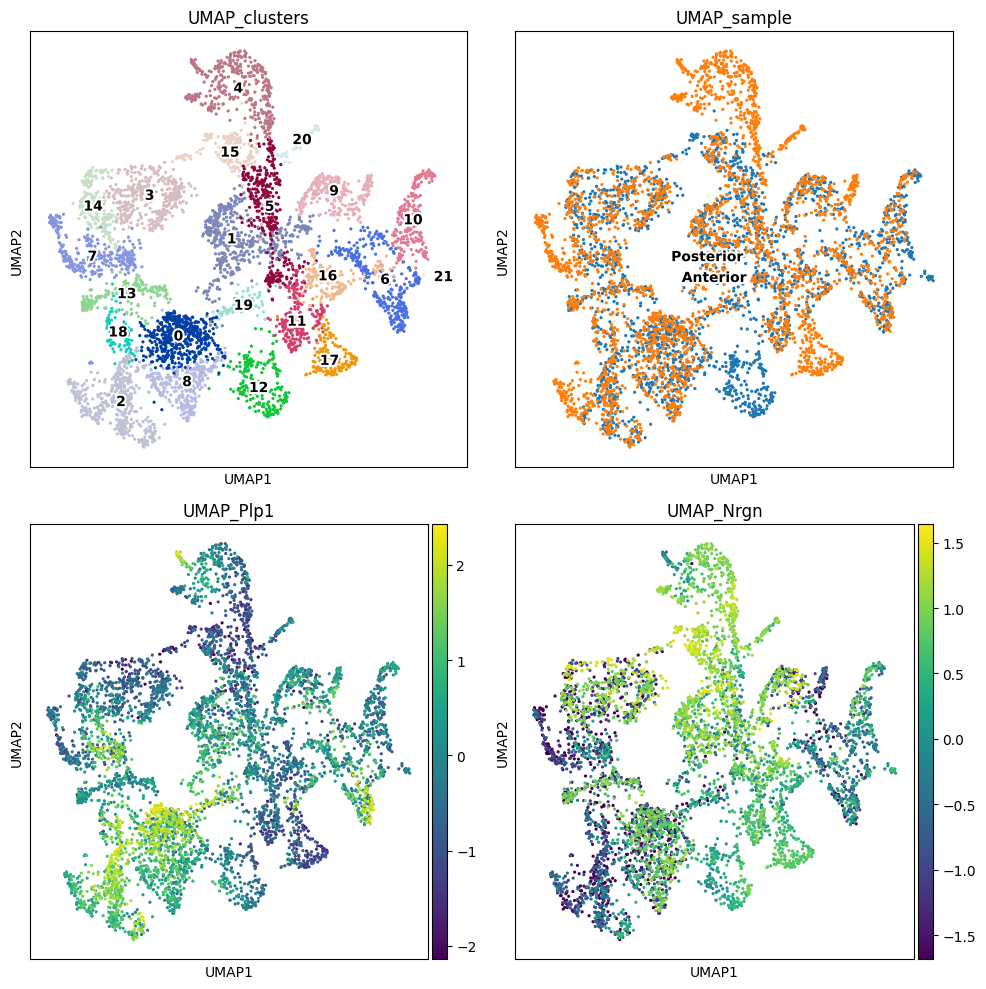

In [77]:
# 创建一个 2 行 2 列（共 4 个子图）的 Matplotlib 画布
# figsize=(10, 10) 设置整个图形的大小
fig, axes = plt.subplots(2, 2, figsize=(10, 10))

# 将 2x2 的子图数组 (axes) 展平为长度为 4 的一维数组，方便通过索引 [0] 到 [3] 访问
axes = axes.flatten() 

# --- 子图 1: 聚类结果 ---
# 在 UMAP 嵌入空间中绘图，根据 'Cluster' 列的细胞或 Spot 聚类结果上色。
# legend_loc="on data" 将图例直接放置在数据点上。
p1 = sc.pl.umap(adata_gt, color="leiden", legend_loc="on data", show=False, legend_fontoutline=3, ax=axes[0]);
# 设置子图标题。
axes[0].set_title("UMAP_clusters")

# --- 子图 2: 批次信息（整合效果） ---
# 在 UMAP 嵌入空间中绘图，根据 'library_id'（批次 ID）上色
# 用于评估批次整合方法（如 GraphST）是否成功地使不同批次（颜色）的 Spot 混合在一起
p2 = sc.pl.umap(adata_gt, color="library_id", legend_loc="on data", show=False, legend_fontoutline=3, ax=axes[1]);
# 设置子图标题。
axes[1].set_title("UMAP_sample")

# --- 子图 3: 标志基因 Plp1 表达 ---
# 在 UMAP 嵌入空间中绘图，根据基因 'Plp1'（通常是少突胶质细胞的标志基因）的表达水平上色
# 用于验证聚类结果的生物学意义。
p3 = sc.pl.umap(adata_gt, color="Plp1", legend_loc="on data", show=False, legend_fontoutline=3, ax=axes[2]);
# 设置子图标题。
axes[2].set_title("UMAP_Plp1")

# --- 子图 4: 标志基因 Nrgn 表达 ---
# 在 UMAP 嵌入空间中绘图，根据基因 'Nrgn'（通常是神经元的标志基因）的表达水平上色
# 用于验证另一个细胞群体的生物学身份。
p4 = sc.pl.umap(adata_gt, color="Nrgn", legend_loc="on data", show=False, legend_fontoutline=3, ax=axes[3]);
# 设置子图标题。
axes[3].set_title("UMAP_Nrgn")

# 自动调整子图及其元素（如标题、图例）之间的间距，防止重叠
plt.tight_layout()

# 显示包含四个子图的最终图形
plt.show()

In [78]:
# 将 GraphST 生成的嵌入结果存储回原始 adata 对象中
# 以便后续的比较结果
adata.obsm['X_GraphST']=adata_gt.obsm['emb'].copy()

In [89]:
# 将 ComBat 生成的 PCA 结果存储回原始 adata 对象中
# 以便后续的比较结果
adata.obsm['X_combat']=adata_combat.obsm['X_pca'].copy()

In [80]:
# 将 scVI 生成的 嵌入结果存储回原始 adata 对象中
# 以便后续的比较结果
adata.obsm['X_scVI']=adata_scvi.obsm['X_scVI'].copy()

In [91]:
adata

AnnData object with n_obs × n_vars = 5591 × 3000
    obs: 'in_tissue', 'array_row', 'array_col', 'library_id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'n_counts', 'clusters', 'cluster_hm', 'cluster_scanorama'
    var: 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_counts', 'means', 'variances', 'residual_variances', 'highly_variable_rank', 'highly_variable', 'mean', 'std'
    uns: 'spatial', 'log1p', 'hvg', 'pca', 'neighbors', 'clusters', 'tsne', 'umap', 'library_id_colors', 'clusters_colors', 'cluster_hm', 'cluster_hm_colors', 'cluster_scanorama', 'cluster_scanorama_colors'
    obsm: 'spatial', 'X_pca', '

### 5.6 比较不同去批次方法

In [94]:
# 使用 scib_metrics 库中的 Benchmarker 类对不同批次校正方法进行性能评估
# 评估指标包括：聚类质量（如 ARI, NMI）和批次混合效果（如 kBET, LISI）
# 目的：系统地比较不同方法在校正批次效应和保持生物学信号方面的表现
from scib_metrics.benchmark import Benchmarker
# 由于评估计算量较大，建议使用多线程加速
# n_jobs=8: 使用 8 个并行进程进行计算
# batch_key="library_id": 指定包含批次信息的列名
# label_key="clusters": 指定包含聚类标签的列名
# embedding_obsm_keys: 列出所有要评估的嵌入结果的键名
# 结果：评估结果将存储在 bm 对象中，可用于生成报告和可视化
bm = Benchmarker(
    adata,
    batch_key="library_id",
    label_key="clusters",
    embedding_obsm_keys=["X_pca", "X_pca_harmony","X_umap_BBKNN_umap",
                         'X_scanorama','X_scVI','X_GraphST'],
    n_jobs=8,
)
bm.benchmark()

/home/puddddd/miniconda3/envs/scvi_env/lib/python3.10/site-packages/scanpy/preprocessing/_pca/__init__.py:227: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  mask_var_param, mask_var = _handle_mask_var(
Metrics:  60%|█████████████████████████████████████████████████████████████████████████▊                                                 | 6/10 [00:06<00:03,  1.11it/s, Batch correction: kbet_per_label]

INFO     10 consists of a single batch or is too small. Skip.                                                      
INFO     11 consists of a single batch or is too small. Skip.                                                      
INFO     14 consists of a single batch or is too small. Skip.                                                      
INFO     3 consists of a single batch or is too small. Skip.                                                       
INFO     5 consists of a single batch or is too small. Skip.                                                       
INFO     7 consists of a single batch or is too small. Skip.                                                       
INFO     8 consists of a single batch or is too small. Skip.                                                       



Metrics:  70%|███████████████████████████████████████████████████████████████████████████████████▎                                   | 7/10 [00:26<00:15,  5.10s/it, Batch correction: graph_connectivity]/home/puddddd/miniconda3/envs/scvi_env/lib/python3.10/site-packages/scib_metrics/metrics/_graph_connectivity.py:32: FutureWarning: pandas.value_counts is deprecated and will be removed in a future version. Use pd.Series(obj).value_counts() instead.
  tab = pd.value_counts(comps)

Embeddings:  17%|█████████████████████████▊                                                                                                                                 | 1/6 [00:27<02:15, 27.13s/it]
                                                                                                                                                                                                          
Metrics:  60%|█████████████████████████████████████████████████████████████████████████▊                      

INFO     10 consists of a single batch or is too small. Skip.                                                      
INFO     11 consists of a single batch or is too small. Skip.                                                      
INFO     14 consists of a single batch or is too small. Skip.                                                      
INFO     3 consists of a single batch or is too small. Skip.                                                       
INFO     5 consists of a single batch or is too small. Skip.                                                       
INFO     7 consists of a single batch or is too small. Skip.                                                       
INFO     8 consists of a single batch or is too small. Skip.                                                       



Metrics:  70%|███████████████████████████████████████████████████████████████████████████████████▎                                   | 7/10 [00:27<00:15,  5.26s/it, Batch correction: graph_connectivity]/home/puddddd/miniconda3/envs/scvi_env/lib/python3.10/site-packages/scib_metrics/metrics/_graph_connectivity.py:32: FutureWarning: pandas.value_counts is deprecated and will be removed in a future version. Use pd.Series(obj).value_counts() instead.
  tab = pd.value_counts(comps)

Embeddings:  33%|███████████████████████████████████████████████████▋                                                                                                       | 2/6 [00:55<01:50, 27.66s/it]
                                                                                                                                                                                                          
Metrics:  60%|█████████████████████████████████████████████████████████████████████████▊                      

INFO     10 consists of a single batch or is too small. Skip.                                                      
INFO     11 consists of a single batch or is too small. Skip.                                                      


... (17 outputs left out)

INFO     5 consists of a single batch or is too small. Skip.                                                       


/home/puddddd/miniconda3/envs/scvi_env/lib/python3.10/site-packages/scib_metrics/metrics/_kbet.py:182: DeprecationWarning: `in1d` is deprecated. Use `np.isin` instead.
  idx_nonan = np.flatnonzero(np.in1d(labs, comp_size[comp_size >= comp_size_thresh].index))


INFO     7 consists of a single batch or is too small. Skip.                                                       
INFO     8 consists of a single batch or is too small. Skip.                                                       


/home/puddddd/miniconda3/envs/scvi_env/lib/python3.10/site-packages/scib_metrics/metrics/_kbet.py:182: DeprecationWarning: `in1d` is deprecated. Use `np.isin` instead.
  idx_nonan = np.flatnonzero(np.in1d(labs, comp_size[comp_size >= comp_size_thresh].index))

Metrics:  70%|███████████████████████████████████████████████████████████████████████████████████▎                                   | 7/10 [04:00<00:48, 16.08s/it, Batch correction: graph_connectivity]/home/puddddd/miniconda3/envs/scvi_env/lib/python3.10/site-packages/scib_metrics/metrics/_graph_connectivity.py:32: FutureWarning: pandas.value_counts is deprecated and will be removed in a future version. Use pd.Series(obj).value_counts() instead.
  tab = pd.value_counts(comps)

Embeddings: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 6/6 [06:13<00:00, 62.33s/it]

                                                    

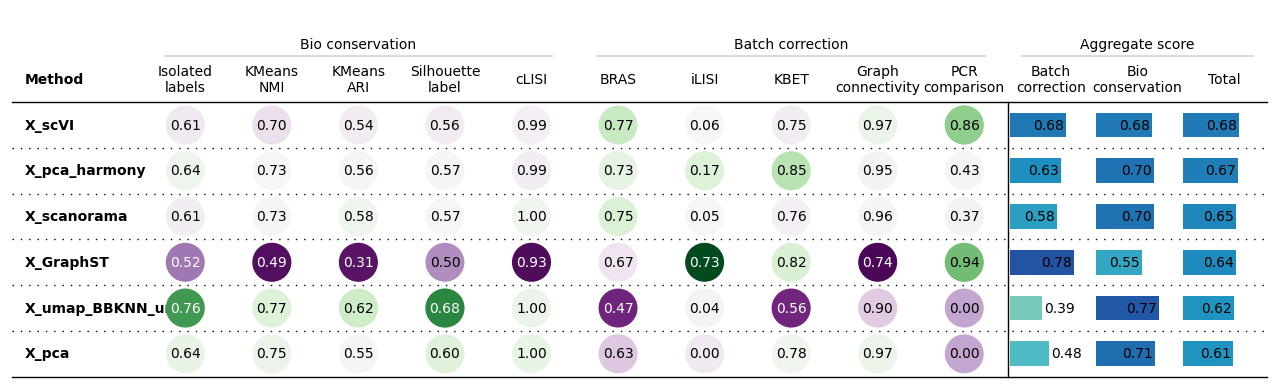

In [95]:
bm.plot_results_table(min_max_scale=False)

这里介绍一下benchmark的参数说明：

**Batch correction**

- Average silhouette width (ASW): 平均轮廓宽度。这是一种用于评估聚类质量的指标，用于衡量细胞在不同批次中是否能够被正确地分开

- Graph integration local inverse Simpson’s Index (graph iLISI): 图集成局部倒数Simpson指数。这似乎是一种用于比较不同图谱（可能是从不同批次收集的）之间差异的方法，可能是通过比较细胞类型或样本之间的相似性来完成的。

- k-nearest-neighbor batch effect test (kBET): k最近邻批次效应检验。这是一种用于衡量数据集中不同批次之间是否存在批次效应的统计方法。

- k-nearest-neighbor (kNN) graph connectivity: k最近邻图连通性。这可能涉及构建一个基于细胞之间相似性的图，以衡量不同批次之间的连接性。

**Bio conservation**

- Isolated label scores: 孤立标签分数。用于评估罕见细胞身份标签的指标。

- Normalized Mutual Information (NMI): 归一化互信息。用于测量两个随机变量之间关联度的度量。在这里我们测量不同batch校正后细胞类型的一致性

- Adjusted Rand Index (ARI): 调整兰德指数。一种用于比较两个数据分区的相似度的指标。

- Average silhouette width (ASW): 平均轮廓宽度。这是一种用于评估聚类质量的指标，用于衡量不同细胞类型中是否能够被正确地分开

- graph cLISI: cLISI。可能是一种用于衡量标签保守性的统计方法，可能与细胞之间的相似性有关。

我们发现，对于批次效应的去除，`harmony` 和 `scVI` 都具有较好的批次效应矫正能力，`bbknn` 能够较好保留罕见群体。考虑到`scVI`需要GPU运算，因此这里我们推荐`harmony`进行批次矫正

# 环境信息

In [ ]:
import subprocess
subprocess.run(['conda', 'list'])

# packages in environment at /home/chenao/.local/share/mamba/envs/st_env:
#
# Name                               Version          Build                 Channel
_libgcc_mutex                        0.1              conda_forge           conda-forge
_openmp_mutex                        4.5              2_gnu                 conda-forge
_r-mutex                             1.0.1            anacondar_1           conda-forge
absl-py                              2.3.1            pypi_0                pypi
access                               1.1.9            pypi_0                pypi
adwaita-icon-theme                   48.1             unix_1                conda-forge
affine                               2.4.0            pypi_0                pypi
aiobotocore                          2.24.1           pypi_0                pypi
aiofiles                             24.1.0           pypi_0                pypi
aiohappyeyeballs                     2.6.1            pypi_0                pypi
ai

CompletedProcess(args=['conda', 'list'], returncode=0)

In [3]:
subprocess.run(['pip', 'list'])

Package                   Version        Build Editable project location
------------------------- -------------- ----- ---------------------------------------------------------------
absl-py                   2.3.1
access                    1.1.9
affine                    2.4.0
aiobotocore               2.24.1
aiofiles                  24.1.0
aiohappyeyeballs          2.6.1
aiohttp                   3.12.15
aioitertools              0.12.0
aiosignal                 1.4.0
anndata                   0.11.4
anndata2ri                1.3.2
annoy                     1.17.3
anyio                     4.10.0
argcomplete               3.6.2
argon2-cffi               25.1.0
argon2-cffi-bindings      25.1.0
array-api-compat          1.12.0
arrow                     1.3.0
asciitree                 0.3.3
asttokens                 3.0.0
async-lru                 2.0.5
async-timeout             5.0.1
attrs                     25.3.0
babel                     2.17.0
bbknn                     1.6.0
bea

CompletedProcess(args=['pip', 'list'], returncode=0)

sckit                     0.0.5
scvi-tools                1.3.3
seaborn                   0.13.2
segregation               2.5.2
Send2Trash                1.8.3
session_info              1.0.1
session-info2             0.2.1
setuptools                80.9.0
shapely                   2.1.1
simplegeneric             0.8.1
simplejson                3.20.1
six                       1.17.0
slicerator                1.1.0
smart_open                7.3.1
sniffio                   1.3.1
sortedcontainers          2.4.0
soupsieve                 2.8
spaghetti                 1.7.6
sparse                    0.17.0
spatial_image             1.2.3
spatialdata               0.5.0
spglm                     1.1.0
spint                     1.0.7
splot                     1.1.7
spopt                     0.6.1
spreg                     1.8.3
squidpy                   1.6.5
stack_data                0.6.3
statsmodels               0.14.5
stdlib-list               0.11.1
sympy                     1.14.0
ta

# 单细胞教程全收录
[B站视频](https://www.bilibili.com/video/BV1S44y1b76Z/):先看一遍视频再去看推送操作，建议至少**看三遍**  
以下的资料都可以在这里订阅：
[scRNA-Seq学习手册Seurat V4修订版](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247510380&idx=1&sn=0eb2b0c519ef1dc25ee8821b736a0fde&chksm=9b3cd03cac4b592ad93149fb4847e6ba3dd03ab69e1ca594ddc64d323fb7496775789cae245d&scene=21#wechat_redirect)    
[scRNA-Seq学习手册Seurat V5更新版](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247519711&idx=1&sn=d25d4f5daf609bda8367f16db676ecf3&chksm=9b3cf48fac4b7d99e65eba6d4c66c63e40b1d187fa1d9e6449d6cd07d5dec5127cff54886f93&scene=21#wechat_redirect)    
[scRNA-Seq学习手册Python版](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504877&idx=2&sn=2b56a9cfa19fcc918ee6c2ed88fed017&chksm=9b3caabdac4b23ab6e28425a4a5eb4d40ee3612e51f84f5d1e53ac91bef93f717e9e754398e3&scene=21#wechat_redirect)    
 
## 单细胞测序基础数据分析**保姆级教程**，代码部分整理在往期推送之中：
[手把手教你做单细胞测序数据分析（一）——绪论](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247499776&idx=2&sn=7fc250d94ed88cfd5e2224f071bb1742&chksm=9b3cb950ac4b30467a082527547b91aec15b7d1f40d44e362894aedeb6a99e014518fa5e4743&token=767842863&lang=zh_CN#rd)  
[手把手教你做单细胞测序数据分析（二）——各类数据结构与读取方法](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247499795&idx=2&sn=68e6298eb43633c71939c146d90230ff&chksm=9b3cb943ac4b3055e09739d77e037d679f3d9ec68780d1aa8c592f806fcc8d2322eaee78752d&scene=178&cur_album_id=2923694853375688706#rd)  
[手把手教你做单细胞测序数据分析（三）——单样本分析](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500010&idx=2&sn=2f9fd1b0101d579bcd250fdc24e98bfc&chksm=9b3cb9baac4b30ac6f0ce28a6dd10470e73d1e1d6defece5636939a32a6db9b2cce0ff8688eb&scene=178&cur_album_id=2923694853375688706#rd)  
[手把手教你做单细胞测序数据分析（四）——多样本整合](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500117&idx=2&sn=cef0b0abec6d73a8c2615980ef68aec1&chksm=9b3cb805ac4b3113fdc820b9c9667f9554b2e39f90c45b5806021a415698b0a5141c521c64dc&scene=178&cur_album_id=2923694853375688706#rd)  
[手把手教你做单细胞测序数据分析（五）——细胞类型注释](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500117&idx=2&sn=cef0b0abec6d73a8c2615980ef68aec1&chksm=9b3cb805ac4b3113fdc820b9c9667f9554b2e39f90c45b5806021a415698b0a5141c521c64dc&scene=178&cur_album_id=2923694853375688706#rd)  
[手把手教你做单细胞测序数据分析（六）——组间差异分析及可视化](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500117&idx=2&sn=cef0b0abec6d73a8c2615980ef68aec1&chksm=9b3cb805ac4b3113fdc820b9c9667f9554b2e39f90c45b5806021a415698b0a5141c521c64dc&scene=178&cur_album_id=2923694853375688706#rd)  
[手把手教你做单细胞测序数据分析（七）——基因集富集分析](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500357&idx=2&sn=40034079b771c478b482e849ed4b216c&chksm=9b3cbb15ac4b3203d517ff71073ab0520fe144bc108b7a26f6b17e88fb63a78c5777946618e3&scene=178&cur_album_id=2923694853375688706#rd)  
[Seurat中分类变量处理技巧](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247486134&idx=1&sn=e581b8ac20bbc968aeef3f9cf56f3a0f&chksm=9b3f73e6ac48faf0f1c81752b0190abc617eb720a71806950e7851c7d19b7e3e092aa97bd005&scene=21#wechat_redirect)    
[Seurat中分类变量处理技巧](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247486134&idx=1&sn=e581b8ac20bbc968aeef3f9cf56f3a0f&chksm=9b3f73e6ac48faf0f1c81752b0190abc617eb720a71806950e7851c7d19b7e3e092aa97bd005&scene=21#wechat_redirect)
  
## 单细胞图片改造计划
[改造单细胞降维图| 1.DimPlot的探索](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247496162&idx=1&sn=598c2920f7cc0697ee5a1fa6cadaee04&chksm=9b3c88b2ac4b01a415feeebbbec6c4891319439dc8dcdafd33cca7a1222e5adc723ae9d3a73d&scene=21#wechat_redirect)  
[改造单细胞降维图| 2.ggplot2中的DIY](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247496239&idx=1&sn=1fe6fd4a7fb88ecc0456b4f5710cb5d6&chksm=9b3c8b7fac4b0269e0abeab951ad6ae0ddd1464dd9d1867280eeb9755fda5ba8f5237d88a7a6&scene=21#wechat_redirect)  
[改造单细胞降维图| 3.3D降维图与动图绘制](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247498080&idx=2&sn=a9bcf65e3ae34ba201e8d49ee33c0728&chksm=9b3c8030ac4b0926c3f059a9a5d23f1bcdbcaf8e5a562eba2b7e3bec3396c44573269bd08e7b&scene=21&cur_album_id=2707677276481814529#wechat_redirect)  
[改造单细胞降维图| 4.一些造好的轮子](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247498191&idx=1&sn=952312a6b26232d460bf787cc276543f&chksm=9b3c809fac4b098972c8c1dd83b9f954a38fe5b5f6bc7e295f3f3a7ba6c4c3d32951679ac24d&scene=21#wechat_redirect)  
[沉浸式统计细胞比例](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503971&idx=2&sn=7dafb1e743ebbb95e488d8d1b7024448&chksm=9b3ca933ac4b2025f922a325ec6893e93613f130ff1d4fd609e2d7274f7f1fdb5134092e28ad&scene=21#wechat_redirect)  
[改造单细胞FeaturePlot](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504616&idx=1&sn=f7b4a0e6b25d224380cd803e3463a3e4&chksm=9b3cabb8ac4b22aeb65e0d6ec32a1f8674dcf907da078ccb3b61e06c4aa035864ebec092f571&scene=21#wechat_redirect)  
[VlnPlot用法及ggplot复现](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504768&idx=1&sn=4fc5eb47037d3a80178e32975488d70b&chksm=9b3caad0ac4b23c61147cfb0f46ecd846568f37ce89c963eb5f069d3e89a8ba285897726bb3d&scene=21#wechat_redirect)  
[VlnPlot的ggplot改造](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504843&idx=1&sn=b795a3e36ae092d8f87abb5a87187828&chksm=9b3caa9bac4b238dd33e905c33924b58aa4ff14e83abbf08046fba7fe765ecb0204163cb6acf&scene=21#wechat_redirect)  
[改造单细胞DotPlot](https://mp.weixin.qq.com/s/GPp-QYwT6jOjFfeZjs9hZg)  
[改造单细胞DoHeatmap](https://mp.weixin.qq.com/s/V_JhpBOy1wG6U-uQsj8CPQ)   

## 3、SCENIC转录因子分析：
[1.绪论](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500098&idx=1&sn=8c31241bd259e303a6ac3c9740f298d9&chksm=9b3cb812ac4b31046fd298c8ee5f0bc0de445df62b234bd934c34ca655e61de3da54d81e2053&scene=21#wechat_redirect)  
[2.学习手册](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500439&idx=1&sn=d6b4874a8352f5b7a4165629c03058ce&chksm=9b3cbbc7ac4b32d158fd3c5c2f155c54c892d40eaae3718409936fc319f69705da32badf79d6&scene=21#wechat_redirect)  
[3.软件安装与数据准备](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500631&idx=1&sn=5d73db4dcc74b66de07dee9db910bb83&chksm=9b3cba07ac4b3311d1820bb305778aea707294f19fd6ff2631cd003da80bdcff8f8bc8ed34de&scene=21#wechat_redirect)  
[4.精简版流程](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501260&idx=1&sn=f1e2a165599e753e2959aad7c8a298cb&chksm=9b3cbc9cac4b358a9499654a2f95fa9010309ee4f408ef8b1f31ceb1a0f263ce22e8b511c430&scene=21#wechat_redirect)  
[5.step1+step2构建共表达网络与regulon](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501692&idx=1&sn=3f7e263a93942ad03faa1ba5f8694ec4&chksm=9b3cbe2cac4b373af9db74a50ffb08a9b8a3b958fc6385c937385f0f7323bc935cdb0fe5275c&scene=21#wechat_redirect)  
[6.Step3 利用AUCell对Regulon评分](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501989&idx=1&sn=2700bf779d7d261a4d751d1635fdce2c&chksm=9b3cb1f5ac4b38e3014476242fe956cf510cc45b9f4cef86070af8094fd5f884f9d5c3a3363f&scene=21#wechat_redirect)  
[7.Step4 二元矩阵的计算与可视化](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503995&idx=1&sn=26c7e9ec56af434e62b02853cfe667d6&chksm=9b3ca92bac4b203d7986645ab5a3fb574f44185c7ced8bd47957fa237d436a95bfa2579d052a&scene=21#wechat_redirect)  
[8.Step5 regulon聚类、分群、降维](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504024&idx=1&sn=143c0ec4d94b8fca0a4a47d3dc24415b&chksm=9b3ca9c8ac4b20de70a87acb2d3f810b0e1497071b1c6f14f1882a6d844fff016e9ba5581eb3&scene=21#wechat_redirect)  
[9.下游探索](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247505276&idx=1&sn=949c753feb85d5877121433caaa33013&chksm=9b3cac2cac4b253affb587a937d3f5e0576851a4f4e1570cb7510a594d155873961bbd91758d&scene=21#wechat_redirect)  
[SCENIC转录因子调控网络图](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247520750&idx=1&sn=496bead1531a7eddd5c286030d350745&chksm=9b3ce8beac4b61a8589a1f8a66bd0571e09c0646655b6d805348bf6f4a0c7b52851615c22868&scene=21#wechat_redirect)  
  
## 上游**fastq**文件处理：
[单细胞分析的最上游——处理Fastq文件：cellranger](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247484923&idx=1&sn=b5876af14fbee68d1e9db4b0f70cd1c8&chksm=9b3f7cabac48f5bdb3aac7d20201d89121a83720b41a10017564fedbb8c4a13df0da92daffd7&scene=21#wechat_redirect)  
[单细胞分析的最上游——处理Fastq文件：dropseqRunner](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247484937&idx=1&sn=4fe1fa518202bdaf462bb93a2614ed32&chksm=9b3f7f59ac48f64fafaf34bac2c80f06d3a86b6a84ccf12566c7eac25bb71c7edd3d74004cf7&scene=21#wechat_redirect)    
[Cellranger报错：Unable to distinguish between](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504739&idx=2&sn=e4e6ad0559b9b6a703d6ab37c2a8fdb0&chksm=9b3caa33ac4b23257424184bda44dd600ad98bc0dfdfa90ab0e3ebaf208e598b0b710fbafa4b&scene=21#wechat_redirect)  
[BD Rhapsody平台单细胞转录组定量流程](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247506542&idx=1&sn=99cf7af7fc0d56b0d6fe7ea3596df2b6&chksm=9b3ca33eac4b2a28e6682a7cf0b2091a387a06ecf89ee10737cf2194286ec0bba472ef1c2b90&scene=21#wechat_redirect)  
[BD Rhapsody定量输出文件读取](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247519706&idx=1&sn=9d084bd8edf6ab4d9184672e5a4a2722&chksm=9b3cf48aac4b7d9c16ef85de7a5f33e65552bbba5d11d2170237063cf754fe9ff376647d3bd7&scene=21#wechat_redirect)  
  
## **细胞通讯**
[跳转B站，连播更方便](https://www.bilibili.com/video/BV1Ab4y1W7qx?p=1)  
**往期推送**  
[《细胞通讯》CellChat学习手册](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501735&idx=2&sn=35fc792961507f4ae1cbae3a2882fba6&chksm=9b3cbef7ac4b37e1417d4108c8bd378c68c3907431ddfc52ad37c916e85649bb450d761a8e19&scene=21#wechat_redirect)  
[《细胞通讯》1.概论](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501282&idx=2&sn=cd37ea80e0b92f5bfbc98ea286e363da&chksm=9b3cbcb2ac4b35a4258d21fe003374795619fc2356376ebbe4ff640233f4b4c6e3e3ead41370&scene=21#wechat_redirect)  
[《细胞通讯》2.1CellChat基础分析教程](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501296&idx=2&sn=fb3e252d95ee8b50cd446e71335b1aa0&chksm=9b3cbca0ac4b35b621b4f51d2c3a130f00461faeeff067396222c2fc2eeb53f3544664d7d9bc&scene=21#wechat_redirect)  
[《细胞通讯》2.2CellChat多组别分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501523&idx=2&sn=6fa803f256c2e0b945f93ae7d8245f50&chksm=9b3cbf83ac4b3695b587e9817840f419104c8680f5ef08ee39aa149b79852f48b179f68e3397&scene=21#wechat_redirect)    
[CellChat空转细胞通讯合辑](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247512011&idx=1&sn=fbd41832c5995d79fead016931d3bfbd&chksm=9b3cd69bac4b5f8d16e7d8b8eeb5490e4938daf68902b06a8d60e25f150ec4ec459796f3aaac&scene=21#wechat_redirect)  
[SeekSpace细胞通讯分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247511890&idx=1&sn=3457b875cd00b4433f50a39a45e1cb8a&chksm=9b3cd602ac4b5f144ad982dfbdf583b56d1bfb768e4e5f2cc9e5424af6e014e752835fadc8a6&scene=21#wechat_redirect)  
                              
## **拟时序分析**
[B站连续播放起来比较方便](https://www.bilibili.com/video/BV1br4y1x7Hf?p=1)  
**往期推送**  
[1.概论](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247486553&idx=1&sn=b689ec962a17ca1a1ada29ae8ff8c019&chksm=9b3f7509ac48fc1f0f81e288de8f15c86548215a1cd9d5c740dc63f2421371d13890398ab1df&scene=21#wechat_redirect)  
[2.monocle概论](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247487001&idx=1&sn=329129e75f703e3f332e76af9c66871e&chksm=9b3f7749ac48fe5f081248c2a48c56685e3915015036c73f8f67ec3e6acc246ddf815daedb22&scene=21#wechat_redirect)  
[3.monocle2实操：精简版](https://mp.weixin.qq.com/s/k-1Jdc0J9EXb2jfwo7935w)    
[4.monocle2实操：完整版](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497730&idx=2&sn=930dc0e276219d70c937e943119388ff&chksm=9b3c8152ac4b08446d457cef3ede4a4a17c0ebacaec0c36efe7d7c8706fb4a3d62222d702ee5&scene=178&cur_album_id=2820794880947159043#rd)  
[5.初识monocle3](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247489044&idx=1&sn=061dbfc34d200b73a8227d0bb28a1d27&chksm=9b3f6f44ac48e65251f7e5ecce84637c05d50ecb92769e8386f221f8e7b9bfeb719232def863&scene=21#wechat_redirect)  
[6.monocle3的降维、分群、聚类](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247489494&idx=1&sn=44f0a44857c12fcf9a1ab84e4f2cbebf&chksm=9b3f6e86ac48e79026321de2fdca81a139d104d655884ffe87a68e0a1551ddffa5af7919d19e&scene=21#wechat_redirect)  
[7.monocle3的拟时序分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247490418&idx=1&sn=18ae0b6139fe1a2436dcf6cc47850297&chksm=9b3f6222ac48eb3450de0b02a34eb5fff2db89ab8f155460d554cbb23be0cd27fd349079e7b2&scene=21#wechat_redirect)  
[解决monocle2的orderCells报错的两种方法](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247491083&idx=1&sn=c5697ab024193cb6595d27e4f4d3bfaf&chksm=9b3f675bac48ee4d7244d9819e14fe210f7e42e40fc7a6a8df7b95bfd92f06334d60d226cb93&token=333450324&lang=zh_CN#rd)  
[一文搞定拟时序分析的下游可视化探索](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497634&idx=1&sn=64872660e8ce80ff08c6c0745c2b241b&chksm=9b3c8ef2ac4b07e4a2ef03870c91fdc1c3ded245dcecd5a2049841cb7e9749bd1cd0852133f1&scene=178&cur_album_id=2820794880947159043#rd)  
  
## 单细胞拷贝数变异
[单细胞拷贝数变异学习手册](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247522733&idx=1&sn=4e3a0707fd8f83b5ad9377bc91ee8e53&scene=21#wechat_redirect)

## scATAC
[scATAC分析学习手册](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247521636&idx=1&sn=208907010f3f7412c1c91343d7dfb0d3&scene=21#wechat_redirect)  
[一文了解单细胞染色质及常见分析](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247522998&idx=1&sn=843d378d3b679951ad3c8e5da7c32d87&scene=21#wechat_redirect)  
[一文了解染色质可及性和表观基因组调控](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247510114&idx=1&sn=f7e8b1df1804a6bba0d79b1ffec2467c&scene=21#wechat_redirect)  
[snATAC联合scRNA揭示小鼠肾脏细胞分化程序和疾病靶点](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247522324&idx=1&sn=62993c2354af1e793fcfd0e06586af17&scene=21#wechat_redirect)  
[百万级单细胞多组学数据集成](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247499336&idx=1&sn=864c535b38ce630487fccc602d893a80&scene=21#wechat_redirect)  

## **scFAST系列**
[01.绪论](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503875&idx=1&sn=2b5ca0c57e17e51abb52adfe199c5736&chksm=9b3ca953ac4b20450f643b94bcfc95aa2b04ded197ce93e455a281901d7ccba099b48cfd03d9&scene=21#wechat_redirect)  
[02.单细胞分析准备工作](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504023&idx=1&sn=4091a22e853242b4aae7a7d3b4008f5c&chksm=9b3ca9c7ac4b20d1bb0389fad5fe85a3c4cf49179747fe97dffaab1087b7d2793668d9f63aa4&scene=21#wechat_redirect)  
[03.fast模块](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504044&idx=1&sn=d37991280217dcc29280efa344f856bb&chksm=9b3ca9fcac4b20eab124ccd4ba6ad3f5eee640df314e7d8fec0225035f06178e3a51dbe2033f&scene=21#wechat_redirect)  
[04.Seurat分析及可视化](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504435&idx=1&sn=c6a6f7ca00684601f3cda49e53be5339&chksm=9b3cab63ac4b2275d993bbaa64c71652685065fa377be57319fc6a5c47eb958b3644c7459cd5&scene=21#wechat_redirect)  
[05.mut模块](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504878&idx=1&sn=2c5d9fc694eaf3e264c38b0691cd3a43&chksm=9b3caabeac4b23a87d201009137572c02ba1ea0dd747bcd8b8c02878b45917b6e235551c41cb&scene=21#wechat_redirect)  
[一文学会scFAST-seq数据分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247505213&idx=1&sn=5f4ed0587dd96149d127a98d36f721f0&chksm=9b3cac6dac4b257bbc00c4647382d27883139bf06ab3071947bf1cccde8d1d501006dabab5f1&scene=21#wechat_redirect)  
  
## 其他单细胞相关**技术贴**:
[应审稿人要求| pseudo bulk差异分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247521437&idx=1&sn=d47b48170f7189b8fb74b2316d0c4898&chksm=9b3cedcdac4b64db43487176203e52e53fe08e01ce819a1615fa1e2f9f8d513bbd4efdee5558&scene=21#wechat_redirect)  
[genesorteR——比FindAllMarkers快一百倍！](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247521266&idx=1&sn=2a74f282222b694f51362445e65c85a6&chksm=9b3ceaa2ac4b63b4a721d1134317af5ee1c9fbe844383a1f404249748e506b674ea26e66d0d2&scene=21#wechat_redirect)  
[单细胞必修课——Seurat流程](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247512220&idx=1&sn=c71bc3f1ef007eb29be8b3b4ec10f0af&chksm=9b3cc9ccac4b40da749d2388dc2d885239a1e4f6ea0989f36b031c7253ce103b061e2605ad8c&scene=21#wechat_redirect)  
[scRNA-Seq双细胞过滤手册](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247511622&idx=1&sn=60b35668e569267bab14ec8fbba8bd74&chksm=9b3cd716ac4b5e00122eac47f55085198040a4a0e97c56895bbc39f3a9f1a1eb4eba27048a8f&scene=21#wechat_redirect)   
[scRNA-Seq学习手册Seurat V4修订版](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247510380&idx=1&sn=0eb2b0c519ef1dc25ee8821b736a0fde&chksm=9b3cd03cac4b592ad93149fb4847e6ba3dd03ab69e1ca594ddc64d323fb7496775789cae245d&scene=21#wechat_redirect)  
[快速上手Seurat V5](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247509880&idx=1&sn=3b7cd169ccfe688d10cb1ca70dc91e91&chksm=9b3cde28ac4b573ec6d5f4bceafa4294c0e9a001b7d0c0b64f274a9978b1438eeccc747ca0c0&scene=21#wechat_redirect)  
[单细胞Figure 1常见图表(视频教程)](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247509260&idx=1&sn=9ff90a428c3f22d43a31ec864e2d8a94&chksm=9b3cdc5cac4b554a2f7cb2a6368f7df9a9a3f6e406eb070663f53d81841a76e188c0b50727de&scene=21#wechat_redirect)  
[SCTransform与ScaleData](https://mp.weixin.qq.com/s/6jwfDa22EUgo2wYpmxCCFg)  
[细胞的数量由誰决定？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247484056&idx=1&sn=4967a054f5241ff3a1bd4a6fe9a502b1&chksm=9b3f7bc8ac48f2deca3141461be035deb8658be184d78597af28f8ba2092d12f020768275248&scene=21#wechat_redirect)  
[单细胞中应该如何做GSVA？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247484701&idx=1&sn=ad90680f252d092a2e21f349c8f32cab&chksm=9b3f7c4dac48f55bf1d11337406ab0e1295e8e1731dbac0715eedc99d11beff7f380e42dd49b&scene=21#wechat_redirect)  
[答读者问（三）：单细胞测序前景](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247484280&idx=2&sn=844af02070012a1c2681880596ba51a2&chksm=9b3f7a28ac48f33e95eb906121be8953410ca4c572c8035cb801609a56caf9dcff57fa989602&scene=21#wechat_redirect)  
[答读者问（四）：如何分析细胞亚群](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247484316&idx=2&sn=e8d02fddc80d1137bb64c55541f1651d&chksm=9b3f7accac48f3da7df7fcad9c996291bc66967c04d16dde92ed391c56e610a7298ac8fb7dbb&scene=21#wechat_redirect)  
[答读者问（八）：为什么Read10X也会报错?](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247485012&idx=1&sn=6007c8d7cb2a236dd7240a678dac0391&chksm=9b3f7f04ac48f612f811c1df9e9450dc8112d343e4bf245be5149c2e2a073d3e339cd0e3ff61&scene=21#wechat_redirect)  
[答读者问（十）整合后的表达矩阵，如何拆分出分组信息？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247485134&idx=1&sn=13f5f8c47d8af2beeca4e103a5f5e26d&chksm=9b3f7f9eac48f688b454a1062ee4e41f7072ac9d58e5466fa7ed4bb05018adbfe167bb3a445a&scene=21#wechat_redirect)  
[答读者问（十一）如何一次性读取一个目录下的cellranger输出文件？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247485145&idx=1&sn=402cb28c16aba0dc647037c9b7aba8f7&chksm=9b3f7f89ac48f69fe27cd427df3eff2e88c240bf20dfe92d8b522eecd7302d132d880bf29047&scene=21#wechat_redirect)  
[给你安排一个懂生信的工具人（十）：不学编程 零代码完成单细胞测序数据分析：Loupe Browser](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247485730&idx=1&sn=42b9b35026bec5359ac34750dea3bf44&chksm=9b3f7072ac48f964970f673a86e27ecd453a80b953168dc110e0ea6bfa4110eeed3350c9601a&scene=21#wechat_redirect)  
[什么？不做单细胞也能分析细胞类群和免疫浸润？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247485798&idx=1&sn=c849bc7a0093af92fc99e13b55842bb2&chksm=9b3f7036ac48f92048d726b38f2dd978d0b0cce779c1a4090aa4da5cb2df3ad30a5c5dbed27e&scene=21#wechat_redirect)  
[答读者问 （十三）查看Seurat对象时的ERROR：type='text'](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247485859&idx=1&sn=a014c4cb6034551e57c70820c7781e49&chksm=9b3f70f3ac48f9e52620e3ff197eb98e58836e8bb6baad634387a521fdda1e4a194356517c73&scene=21#wechat_redirect)  
[各类单细胞对象（数据格式）转换大全（一）](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247485925&idx=1&sn=14e08440200f0f5cb4dcc2dc615efeb8&chksm=9b3f70b5ac48f9a37a43cc2a8b2a5e485a3f84b4ef87949dfe99056bc6301b110e80800f6bb1&scene=21#wechat_redirect)    
[单细胞对象(数据格式)转换大全|2. h5ad转Seuratobj](https://mp.weixin.qq.com/s/iYz4ZsD-oJ2ZJsZpbGKRsg)   
[批量整理好GEO中下载的单细胞数据](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247486045&idx=1&sn=0b6874bcffc8abafb505cabce4c4fc0e&chksm=9b3f730dac48fa1b140ef01c07a7749e69df4fa7d2056deeed0673c668b6246724cd85741125&scene=21#wechat_redirect)  
[答读者问 （十四）Seurat中分类变量处理技巧](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247486134&idx=1&sn=e581b8ac20bbc968aeef3f9cf56f3a0f&chksm=9b3f73e6ac48faf0f1c81752b0190abc617eb720a71806950e7851c7d19b7e3e092aa97bd005&scene=21#wechat_redirect)  
[答读者问 （十五）稀疏矩阵转matrix, as.matrix函数是下下策](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247486259&idx=1&sn=97de5c9e15e48cb62c8a680376a4ee0d&chksm=9b3f7263ac48fb75a91b40416826fe35b340284cf38255925ac447443a62cdc1df082d20fb61&scene=21#wechat_redirect)  
[答读者问 （十六）做单细胞测序到底需要多少内存](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247487923&idx=1&sn=15043c6d729b0d5493ab875b0e54a259&chksm=9b3f68e3ac48e1f5dae514a01c857f9a56a90e2977dd7862db28d06fe55888cd9bb4afbb14e0&scene=21#wechat_redirect)  
[答读者问 （十七）调用的线程越多就算的越快嘛?](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247488995&idx=1&sn=7140e0d037671542fb37dff3a3c94b28&chksm=9b3f6cb3ac48e5a5f54a02be9e6af9f5a4cf8da1de1770f9035130c84dedf059a024964fc15a&scene=21#wechat_redirect)  
[答读者问（十八）、一个我至少被问过30遍的monocle报错](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247490010&idx=1&sn=24c55fa4bd5d7d829625cb67dbaf321a&chksm=9b3f608aac48e99c9f27e3423c8398034a1819d0ccebbf21170b955461d2c335132d6f3cce25&scene=21#wechat_redirect)  
[一文搞定单细胞基因集评分](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497831&idx=2&sn=82fa51c76a381fba0b444e9b6b23eb5f&chksm=9b3c8137ac4b0821dfb62e9b365ea3c32abbbd80df42df63181c37ad9ed991c0183c2c7981d8&payreadticket=HCkRKr7R3-O3p5-0VkAwOOfgIXR8STjX9HoZYYWKS3jgJtptsG2Mu4KWI6Pz6cAuCOxiFPM#rd)  
[没有barcode文件的单细胞数据要怎么读取](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247490952&idx=1&sn=364a3941e59e45234795c906a42fc9ab&chksm=9b3f64d8ac48edcec70384cf5c6a91224d0f7841ce3a7cfcade6513500c13673a6695d6f0299&token=1760636281&lang=zh_CN#rd)  
[单细胞基因集评分之AUCell](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247491761&idx=1&sn=41f5c1ceaacf6a1c4840567f8a349e06&chksm=9b3c99e1ac4b10f7ca158561e96fec76a49ff32b8412cb146ed3fb7aa9260c75172b4eb16f9a&scene=21&token=7173752&lang=zh_CN#wechat_redirect)    
[如何加快Seurat的计算速度](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247494116&idx=1&sn=f3dc577cbb464779062aada313191a05&chksm=9b3c90b4ac4b19a27a17f958e3437337d5b10b6ba7153e4dd43dedcb4df812d8c6b4d86fe970&token=416896563&lang=zh_CN#rd)  
[粉丝来稿|1. Seurat4相较于Seurat3的几点改动](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247494516&idx=1&sn=cb2d4e6b182428ce7b98e7fff2e8729a&chksm=9b3c9224ac4b1b32c4fe99758960305c4845395cfe03851d70a0407043ee36250e55d20106fc&scene=21&token=1634975705&lang=zh_CN#wechat_redirect)  
[如何加快Seurat的计算速度](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247494116&idx=1&sn=f3dc577cbb464779062aada313191a05&chksm=9b3c90b4ac4b19a27a17f958e3437337d5b10b6ba7153e4dd43dedcb4df812d8c6b4d86fe970&token=468535359&lang=zh_CN#rd)      
[答读者问（二十）四个单细胞样本只给了一套文件怎么读](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247494879&idx=1&sn=c2287ab3684792747dfac53d6704462b&chksm=9b3c958fac4b1c994a4b075c4f8475816e121966fa8c52cb0a2ce8c14987988ab9bdb49bdf69&token=468535359&lang=zh_CN#rd)
[人类单细胞测序数据中有哪些以"**-"开头的基因](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247495019&idx=1&sn=f52ac22ca1ea47ecddaa3503bdc2c0b6&chksm=9b3c943bac4b1d2d521f7155ce8f499389dade23828017572a84cdce71e5d08d37d74e08512b&scene=21&token=1624480671&lang=zh_CN#wechat_redirect)  
[为什么总把分辨率调的很高](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247495765&idx=1&sn=2ec5e3e26491e28c92e25c40630bffae&chksm=9b3c8905ac4b0013a23f9cda2cccd67cdf3c4a941bac161e3a15a12ab98cd4e5eca8aeedbe96&token=133749967&lang=zh_CN#rd)            
[答读者问（六）：Seurat中如何让细胞听你指挥](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497669&idx=3&sn=ac3408c7dd28425426d954f81d283252&chksm=9b3c8e95ac4b0783c12182a960e8158c8a0992a20335f8c70f1dc63855c5984dd22e4dee706d&scene=178&cur_album_id=2820794880947159043#rd)  
[答读者问| 22.object 'CsparseMatrix_validate' not found](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247496273&idx=1&sn=fd5a92dd7fdc349b1624784ca74b1220&chksm=9b3c8b01ac4b0217cf06d89bfea49c3fa0c9b580957338c0cc8f55ede3e8f65d6d7162ae27e3&scene=21#wechat_redirect)  
[单细胞数据在R中的读取及存储速度太慢怎么办？这个神包来帮你！](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500270&idx=1&sn=11bdf3c7f9042fc03f9ed237a9b9677b&chksm=9b3cb8beac4b31a8bf1d9fb862553ed32ac9a56f4a6e0f2d38c9478132f87327d8c6b6940573&scene=21#wechat_redirect)  
[单细胞分群分辨率选择困难症](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501241&idx=1&sn=9e15d23f721ad7f4ae1335ce5362031b&chksm=9b3cbce9ac4b35ff43434c0384afbbf5689f5b62a677e55e8a635d4812da57593d85a73cf48b&scene=21#wechat_redirect)  
[一文搞定空间转录组与单细胞测序的整合分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507210&idx=1&sn=f32037ffefd60b0d1bcca7bf9c3e0823&chksm=9b3ca45aac4b2d4cf0c68299db3a2891130d89d9e0fe2a9ecb34b394736550bcf7d7c51090cc&scene=21#wechat_redirect)  
[一文掌握十个单细胞数据库](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507979&idx=1&sn=e94225b592733f2e22b4b09245027365&chksm=9b3cd95bac4b504df8dc25d9c5cfddf56d3b47e7cc6f33a7ef369bc916c60abb6b49277b79f7&scene=21#wechat_redirect)  
[如何将已经构建好的Seurat空转对象转存为原始文件？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247508133&idx=1&sn=297b8fb9cc8f33a1d19167dba1104e97&chksm=9b3cd9f5ac4b50e36df53e3e18bb2990d9635d88a725f1e54fc5eb5967ac9f0934b79cbb8b34&scene=21#wechat_redirect)  
[一文学会零代码单细胞分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247511007&idx=1&sn=e7be3d9775890e5717889714629cfaf5&chksm=9b3cd28fac4b5b9936428d5f74d8b581b5cddc18d0fc42e2a5d75604cce080588d50f1304a17&scene=21#wechat_redirect)  
[SeekSpace| 会单细胞就会空间转录组](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247511779&idx=1&sn=23868525d86a9ed7867a3837ed18612c&chksm=9b3cd7b3ac4b5ea502950d0278d68da978f6011b2597c3ec90fb77e79320883fb4a5be2d5399&scene=21#wechat_redirect)  
[10xGenomics官方可视化工具——Loupe Browser](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247519698&idx=1&sn=0135ef1763fc146252835f2bd7f728ec&chksm=9b3cf482ac4b7d949d0936f11b487d5da4fd8f235bb86f63e960e23785885b9db0d14897b63d&scene=21#wechat_redirect)  
[快速上手Cellranger](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247521051&idx=1&sn=e2ab820001013bae6e35310e27897086&chksm=9b3cea4bac4b635ddbb74c29240896902b497cdc47f1f37d99fa0fb8a402375e513690f24e3f&scene=21#wechat_redirect)    
[单细胞/空转生信工程师自测卷(入门级)](https://mp.weixin.qq.com/s/2RvmlET91UkS-13pu3ZrVw)
[30w单细胞数据会吃掉多少内存？](https://mp.weixin.qq.com/s/0WoO08Yb80g7sa_R8s1ZwQ)

              
## 单细胞文献阅读
 [《Advanced Science》新型Arf1抑制剂促进癌症干细胞衰老并增强抗肿瘤免疫](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247522233&idx=1&sn=287a380de741ff55f0ce78dc9c727985&chksm=9b3ceee9ac4b67ffd925abafeba2cb215a5984e6dc85f0d8607340a07ec9208f1d19eae0e04b&scene=21#wechat_redirect)  
[IF14.3| scRNA-seq+脂质组多组学分析揭示宫内生长受限导致肝损伤的性别差异](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247520900&idx=1&sn=157134292ffc2e5df730c5ba8a357b61&chksm=9b3cebd4ac4b62c286543c30381e9b4fdb8b44b28d4fa902fb963bbd45b28e1d3f1bc98eb148&scene=21#wechat_redirect)  
[Q1临床设计+生信分析，单细胞揭示骨髓增生异常综合征中的造血功能异常&微环境中的细胞状态](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247520295&idx=1&sn=8f98781c4ecc8205bcfd2cfa86caed9c&chksm=9b3ce977ac4b60617583775dcd4f0b2e3133a4fec23f7c9b95ae42b26bae9b8f6ddcd1f5ccb0&scene=21#wechat_redirect)  
[13分+文章利用scRNA-Seq揭示地铁细颗粒物引起肺部炎症的分子机制](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247511886&idx=1&sn=31c712d00377b0f0ed33703b5b4fbfd8&chksm=9b3cd61eac4b5f084fde14a2eb50356f2f40a66c608d38909f12a3d81f48cff029a09ce2ee8c&scene=21#wechat_redirect)    
[除了铁死亡，还有铜死亡？！](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247518144&idx=1&sn=d036f1bb04b09eb73f53e2104d69404c&chksm=9b3cfe90ac4b77862f2f463b42132c7bfdb687a1b61d350dcf656117b1331271e179710fd4fa&scene=21#wechat_redirect)  
[scRNA-seq揭示脓毒症预后水平预测的关键靶点！](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247522281&idx=1&sn=f95eb12fdc340b8da1123ec6253e6fac&chksm=9b3ceeb9ac4b67afa587e5fa3a2a8960e9bb28a1ad6dc48e49120a76154417a4c8be95af90b0&scene=21#wechat_redirect)  
[《Narure Biotechnology》教你怎么"捏造"单细胞数据](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247521498&idx=1&sn=925561221f12e2ef2846b897914cc692&chksm=9b3ced8aac4b649c9073ec8dcaae49d689acfaf3d2d8b0012b727ef75b8231088b4e176fa9ca&scene=21#wechat_redirect)    
[拟时序分析神包—monocle的三篇《Nature》](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247519064&idx=1&sn=173948cb696c7d33b90cd21b28986777&chksm=9b3cf208ac4b7b1e328fdc445f9aecd6cfb836fdb33767876ba1aa35c55098a2a071dbe8e2f0&scene=21#wechat_redirect)  
[测序技术的发展与应用](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247495792&idx=2&sn=1aecc80b68f65f8a44a899df524038c0&chksm=9b3c8920ac4b0036b23268331b457a335b22b4fa3aed1db287ab79e7a4613df8d195bd11421a&scene=21#wechat_redirect)  
[单细胞测序解析糖尿病肾病中肾小球的动态变化](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497682&idx=2&sn=7ef49191c5e334bb291ccdaa8ea444ae&chksm=9b3c8e82ac4b079425433938c831d528eddb9237efaca49acbc210e9cd715d057541589dc290&scene=178&cur_album_id=2802463431357661184#rd)  
[单细胞测序技术解析健康人与T2D患者的胰岛差异](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497713&idx=1&sn=b7f8df758bc4d95b88969378c6dfbeee&chksm=9b3c8ea1ac4b07b7c6a0b5023ebf6c8ecd7d34741ab076baa0b564535d1d753bbf9dc5be5290&scene=178&cur_album_id=2802463431357661184#rd)  
[小鼠全肾单细胞测序开篇之作](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497713&idx=2&sn=554d6a4e1b28b2e5303695fae5942a34&chksm=9b3c8ea1ac4b07b72323ce25cd49474a9228ec1aaa56243f57dca3f2f668dc42ab9cd58dca21&scene=178&cur_album_id=2802463431357661184#rd)  
[Nature也能白嫖？](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497867&idx=2&sn=caeb8ed06ffd5239b58cebcd90843cf8&chksm=9b3c81dbac4b08cd9eec50978951a1b890ca08edec644ff75205a09ad1f067dff25d6ecb938e&scene=178&cur_album_id=2802463431357661184#rd)  
[一篇不花钱就能白嫖的文章](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497840&idx=2&sn=1dacbfb190e11d2ff104e32f238cf8c4&chksm=9b3c8120ac4b08367bfe3a0dd8d55f21f5d13528826de3144a9a85ce9b1c9f4c710de703edae&scene=178&cur_album_id=2802463431357661184#rd)  
[高氧下小鼠肺发育损伤的ScRNA图谱](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247498513&idx=2&sn=79845edf56a3023c59c73403d7b6494b&chksm=9b3c8241ac4b0b57793402686edc8c35aaa3b0959d3096b5122207fbb70ab809d1df5faee0d7&scene=178&cur_album_id=2802463431357661184#rd)  
[文献阅读（十二）、IgAN & STRT-Seq](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247485376&idx=1&sn=02e228d0993d8a653c8bb1d531021cdb&chksm=9b3f7e90ac48f78686d6d5953aeb192db4f28bf577dbebd76d9fabbe797f135b7fb08fb42867&scene=21#wechat_redirect)  
[老树开新花——EGFR、肿瘤、免疫+scRNA-Seq](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247498596&idx=2&sn=8f63f5856cdf90e15f1d19b4cfe6a39e&chksm=9b3c8234ac4b0b221a5d2c417558f0e63f742459c0a3f8c1cbb4cdf74ce25ddcaf0e48f4a7ce&scene=178&cur_album_id=2802463431357661184#rd)  
[癌前基质细胞驱动BRCA1肿瘤发生](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247498597&idx=2&sn=9f5fee38d0821052c9c6b3753c2b3bed&chksm=9b3c8235ac4b0b238c4902ad7b3944b285baaa0a7ec6f5c7d08a596fdf89735dc7a7afab91f0&scene=178&cur_album_id=2802463431357661184#rd)  
[文献阅读（十八）、紧跟生信"钱"沿,胰腺癌&免疫多模态图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247489045&idx=1&sn=29feb00f094a9a7e20418b22aa54dd8c&chksm=9b3f6f45ac48e653d4223838eb1d96e65e5ee51ac3f7782841d9b33013bdb67b5e22e9599fac&scene=21#wechat_redirect)  
[文献阅读（十九）、原发头颈癌和肿瘤转移微生态](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247489511&idx=1&sn=76ec706ebd97e3edd08687f5cf3b6816&chksm=9b3f6eb7ac48e7a10bb81aec5332ecc0544a683f576ea680c8baa621e504816bf65c7d331bdf&scene=21#wechat_redirect)  
[文献阅读（二十一）、肾脏疾病&代谢&核受体ESRRA](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247490575&idx=1&sn=b931a1d50ddcfc4e34999763139695a0&chksm=9b3f655fac48ec49eb2fb01ce8acb15e230091ab3c29ce1471747850be5dae54dbe97fd103b0&scene=21#wechat_redirect)
[文献阅读（二十二）、PD-1&急性髓细胞性白血病&T Cell](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247490929&idx=1&sn=82bf93ccbd9dd906caad8ec709c86153&chksm=9b3f6421ac48ed37117794e7c5b878fa78760627e8bced9c37a2c7c67fd8afd58d0cf0add17e&token=1760636281&lang=zh_CN#rd)  
[文献阅读（二十三）鼻咽癌微环境&scRNA](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247491084&idx=1&sn=e450844d4f102caa88cab6deb630a3f4&chksm=9b3f675cac48ee4a6883559859a21d77256479bb8d030c54a91240827d85b925066bc4f8ebb6&token=333450324&lang=zh_CN#rd)  
[文献阅读(二十四)、《Nature》：MYB调控衰竭性T细胞对检查点抑制的响应](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247491909&idx=1&sn=5d47d2917397248dd6a3a9e85f2acd6d&chksm=9b3c9815ac4b11037e52ba00215a0b6cd23b554139955123ef21ac2cd07a646e97309e7def78&scene=21&token=7173752&lang=zh_CN#wechat_redirect)  
[文献阅读(二十八)、单细胞都能活检测序了？](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247493604&idx=1&sn=d0f8738e26a4b1c870d329b6a4a7b689&chksm=9b3c9eb4ac4b17a2d0b04d72c350c20f575701de7179f77fcd3567f4b1533cf35df4157f67e1&token=416896563&lang=zh_CN#rd)  
[文献阅读(二十九)、单细胞测序做到什么程度能毕业|硕士篇](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247493808&idx=1&sn=52c7d330ffdda47c3409d36fe9cbbcd8&chksm=9b3c91e0ac4b18f6edf59d171a0d982b1e3f842148046d8eed19343484feaa84dbd5b7682a11&token=416896563&lang=zh_CN#rd)  
[文献阅读(三十)、单细胞测序做到什么程度能毕业|博士篇](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247494017&idx=1&sn=a2dc4e2eef2bcdb40f5074b665dfa45f&chksm=9b3c90d1ac4b19c79ac5128f96d27789241357c9745bb0389ff5f79f96ab825d3e1c9b29e3af&token=416896563&lang=zh_CN#rd)  
[2022年了，都有哪些器官/组织有scRNA-Seq数据|小鼠篇](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247494796&idx=1&sn=92c91a65719bdf39658814eb691a780f&chksm=9b3c95dcac4b1cca5547440a5881e650da3ea430bad3e6017cbd2891606b2ec40e3ec343bc0e&scene=21&token=468535359&lang=zh_CN#wechat_redirect)  
[2022年了，都有哪些器官/组织有scRNA-Seq数据|人类篇](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247494806&idx=1&sn=1d15ad9cb4d350a164d3b941bc715233&chksm=9b3c95c6ac4b1cd054cedbd3e8c8f57ee88cc59a6ebda2fd11ba8fea79f5e9e8c65d21ff338c&scene=21&token=468535359&lang=zh_CN#wechat_redirect)  
[2023年了, 都哪些物种有scRNA-Seq数据](https://mp.weixin.qq.com/s/otvcVXJDMbF_hdQPaPw5hQ)   
[终于读到一篇用monocle3做拟时序的文章](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247496064&idx=1&sn=0be38306f9cd8c6b819d58cc2e779b87&chksm=9b3c88d0ac4b01c6773b6c4f1a063788509baa27c57e2098b16b8ebe38cc625a87b9d89272c7&scene=21&token=445940587&lang=zh_CN#wechat_redirect)  
[单细胞转录组+亚细胞空间代谢组=25分文章](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247496126&idx=1&sn=8cb6040a38eb844bb215c0d395196e3a&chksm=9b3c88eeac4b01f8dcb8f4c7a19c5a58841d5fe1623f0a4c585c6dcc281cbbdd2830a1150f6a&scene=21&token=445940587&lang=zh_CN#wechat_redirect)  
[基于scRNA-Seq&空间转录组的AKI研究](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503664&idx=1&sn=39519d9cfa54e2d5b757f6c249ccbc86&chksm=9b3cb660ac4b3f768c8cfb708d8355c426b2d4ad39538acd5584aa9741ccdf1076b7112492df&token=436478285&lang=zh_CN#rd)  
[《Nature Methods》: NiCheNet, 能够考虑到胞内转录调控的细胞通讯软件](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503617&idx=1&sn=18389ffe1d201b1c0592ebc923aac851&chksm=9b3cb651ac4b3f4777cb0a6282ad99cd2aad711050d1590f20f970d843f05fb42f8cc02833e2&scene=178&cur_album_id=2802463431357661184#rd)      
[数百万级单细胞数据时代的多组学分析](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503603&idx=1&sn=c146eec4528f418226f0103030cb803c&chksm=9b3cb7a3ac4b3eb5bd8be7e41c8c440c80e8223fb10634bfc6d523fe389e3aa0bc14e5ea87d5&scene=178&cur_album_id=2802463431357661184#rd)  
[两万字长文|当前单细胞 RNA-seq 分析的最佳实践](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503544&idx=1&sn=d563497cc912950d07c2284709f3aede&chksm=9b3cb7e8ac4b3efe66fa4e743f9d6c245a7dd6ea370cd0ee397e92761a2d680cac5c6dd4ea87&scene=178&cur_album_id=2802463431357661184#rd)  
[《Nature》: 单细胞解析大脑感知流感过程](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503508&idx=1&sn=72781ff97ecae1c32815fe2c4d71b24e&chksm=9b3cb7c4ac4b3ed2b46c8c22f4ce8f93e3f93004ee76542bdd92039d301cec4a10077bb973db&scene=178&cur_album_id=2802463431357661184#rd)  
[scRNA-Seq+WGCNA+铁死亡：IF=9.69](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503498&idx=1&sn=fcf38bd6fd1dbaf80e203926bb63d5c4&chksm=9b3cb7daac4b3ecca9f2dd590fc581f5b1ae67a7f89be6f76eb438a017b5c335d8a01830b6a5&scene=178&cur_album_id=2802463431357661184#rd)  
[<IF=27.4> IgG4相关性疾病中颌下腺和血液中的细胞和分子改变](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503081&idx=1&sn=29890957ab75f050d466ca659292b529&chksm=9b3cb5b9ac4b3cafe279783c49cf7928819c5caeffbc34e52ae0c79f5e701ce8a25dd6f0c913&scene=178&cur_album_id=2802463431357661184#rd)    
[急性心肌梗塞(AMI)外周血scRNA-Seq分析流程及结果梳理](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500943&idx=1&sn=c85cf5be55fa2ae4b85c70ca7e4dfffc&chksm=9b3cbddfac4b34c99abb307f71883ca495e2ed876556a7ad064a3cd69e17827dc534317b372e&scene=178&cur_album_id=2802463431357661184#rd)  
[酸了，六个样本的scRNA-Seq+差异分析=9分文章](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500273&idx=2&sn=c95ac7ceecce0e6364f49e75058caabe&chksm=9b3cb8a1ac4b31b76b36635ac5e3d3385db6cc8c3fa916541bcb61d9a3ad4417f4bfdaa10274&scene=178&cur_album_id=2802463431357661184#rd)  
[自测scRNA-Seq+scWGBS=3分三区文章？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247498939&idx=1&sn=1b33d219c795f2de8ff66a5c330a3d24&chksm=9b3c85ebac4b0cfd050a7c0abe11dead991a988aa5b790eac6fd57de2f76a85ef2191d8b9ca6&scene=21#wechat_redirect)  
[百万级单细胞多组学数据集成](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247499336&idx=1&sn=864c535b38ce630487fccc602d893a80&chksm=9b3c8718ac4b0e0e8a0e2560a83546167a82616d99503606e3ac0ef29e90b01cc762e95d64e6&scene=21#wechat_redirect)  
[空间转录组与单细胞转录组整合分析工具大比拼](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500243&idx=1&sn=b0e513e85a202ec7ca4041a700a7ae10&chksm=9b3cb883ac4b3195cffd0398d880468b12dd068f9a9fd96b7d0f8aed8961be34293e6ff4a2bb&scene=21#wechat_redirect)  
[<IF=27.4> IgG4相关性疾病中颌下腺和血液中的细胞和分子改变](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503081&idx=1&sn=29890957ab75f050d466ca659292b529&chksm=9b3cb5b9ac4b3cafe279783c49cf7928819c5caeffbc34e52ae0c79f5e701ce8a25dd6f0c913&scene=21#wechat_redirect)  
[微生物组研究技术——微生物也能做单细胞](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247488278&idx=1&sn=3662cde0f439a7e7cad7fb0d50082c05&chksm=9b3f6a46ac48e350318b38f1bfe252dd4c315ad058dc4b9aa02fadf2be2291fd0dac50f24cc6&scene=21#wechat_redirect)  
[scRNA-Seq+WGCNA+铁死亡：IF=9.69](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503498&idx=1&sn=fcf38bd6fd1dbaf80e203926bb63d5c4&chksm=9b3cb7daac4b3ecca9f2dd590fc581f5b1ae67a7f89be6f76eb438a017b5c335d8a01830b6a5&scene=21#wechat_redirect)  
[《Nature》: 单细胞解析大脑感知流感过程](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503508&idx=1&sn=72781ff97ecae1c32815fe2c4d71b24e&chksm=9b3cb7c4ac4b3ed2b46c8c22f4ce8f93e3f93004ee76542bdd92039d301cec4a10077bb973db&scene=21#wechat_redirect)  
[两万字长文|当前单细胞 RNA-seq 分析的最佳实践](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503544&idx=1&sn=d563497cc912950d07c2284709f3aede&chksm=9b3cb7e8ac4b3efe66fa4e743f9d6c245a7dd6ea370cd0ee397e92761a2d680cac5c6dd4ea87&scene=21#wechat_redirect)  
[数百万级单细胞数据时代的多组学分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503603&idx=1&sn=c146eec4528f418226f0103030cb803c&chksm=9b3cb7a3ac4b3eb5bd8be7e41c8c440c80e8223fb10634bfc6d523fe389e3aa0bc14e5ea87d5&scene=21#wechat_redirect)  
[《Nature Methods》: NiCheNet, 能够考虑到胞内转录调控的细胞通讯软件](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503617&idx=1&sn=18389ffe1d201b1c0592ebc923aac851&chksm=9b3cb651ac4b3f4777cb0a6282ad99cd2aad711050d1590f20f970d843f05fb42f8cc02833e2&scene=21#wechat_redirect)  
[基于scRNA-Seq&空间转录组的AKI研究](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503664&idx=1&sn=39519d9cfa54e2d5b757f6c249ccbc86&chksm=9b3cb660ac4b3f768c8cfb708d8355c426b2d4ad39538acd5584aa9741ccdf1076b7112492df&scene=21#wechat_redirect)  
[自测蛋白质组+Bulk RNA-Seq & 挖掘scRNA-Seq=13.6分JASN](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504408&idx=1&sn=da427a6687b06a82d9dd58ae9f9aa474&chksm=9b3cab48ac4b225e8272d0475ae9295c1ea96172419aa604526f1b8a898748cb3897508d95a0&scene=21#wechat_redirect)  
[非监督式聚类在scRNA-Seq应用中的挑战](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247505257&idx=1&sn=a524a42b966007defbb2529d300d4c28&chksm=9b3cac39ac4b252f9f88181b932fdc279507c2affc765b53dbccf73084f86f0de25ab1af39bc&scene=21#wechat_redirect)  
[Seurat V5的《Nature Biotechnology》](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247505826&idx=1&sn=5b9e4aeb41fc2f2943aeac9e22d4d038&chksm=9b3caef2ac4b27e4d57e75a508f00b5605ab99a7b51024110f54778683e14ed8bbcd743f0588&scene=21#wechat_redirect)  
[当空转遇上单细胞~](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247505721&idx=1&sn=19d02b3858ebcf483d9e071b8ba00092&chksm=9b3cae69ac4b277f5b90fd75819ac8435226ad6daaf744f367d49ceb8099408e097d48656e2f&scene=21#wechat_redirect)  
[人类肾脏参考组织图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247506567&idx=1&sn=e895c0d5a6dde49be76429e9961e61bf&chksm=9b3ca3d7ac4b2ac15dc4e2665e5d624b92bf85d8c94ac70c26e476444451c40a5286c853628f&scene=21#wechat_redirect)  
[有免疫特征的基质细胞，有没有可能是双细胞？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247506493&idx=1&sn=ed65c6b0738a1fb8492da0b4ecdc9c63&chksm=9b3ca36dac4b2a7b4ca45f169526c6ed51777e20811d50c2892e683eee405c25607a42cc7a66&scene=21#wechat_redirect)    
[CAR-T治疗急性髓细胞性白血病的scRNA-Seq图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247506371&idx=1&sn=a9f44bdfd795a4d04615bc307cd23cf5&chksm=9b3ca093ac4b29853f7f068e3969384ed07cd2cf4d64a55c423cd74bce83b914c96844a4cb3d&scene=21#wechat_redirect)  
[临床样本+单细胞+空转=IF4.8？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247508744&idx=1&sn=1bc02443acab6d1720fe64e0334ce57a&chksm=9b3cda58ac4b534e3bf7ed2ab225d104d9976c5dc21b8443f88d3a555c5db67449b622ac91b4&scene=21#wechat_redirect)  
[鼻咽癌的Bulk RNA-Seq与scRNA-Seq联合分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247510548&idx=1&sn=58048c46e837b1d56dffa282272c6d96&chksm=9b3cd344ac4b5a52369e91b4e61fa0a2c951b82cc21165b99f42ba2c2191d4add803bd73c928&scene=21#wechat_redirect)  
[GPTCelltype：玩GPT4玩出Nature](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247510790&idx=1&sn=b56acf349e417f4ce1a09485256a5f87&chksm=9b3cd256ac4b5b400af5a809c5f595c8e1442513d277501c5bca1c80ce85f18a06a1d8994a9c&scene=21#wechat_redirect)  
[《Nature Methods》教你如何挑选空转平台](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247520891&idx=1&sn=147d185643bd5dbba4e58b20b2eed872&chksm=9b3ceb2bac4b623d0273eb53b44709e951a493d79338d622b07e256cb4bf385c7d77983e7f48&scene=21#wechat_redirect)   
[一文了解sc与sn的异同](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247526966&idx=1&sn=9b2aaa1059e6ed68ada65fe004190108&scene=21#wechat_redirect)
                                         
## 单细胞注释复写
[单细胞注释复写(一):Human Fetal Kidney](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247490504&idx=1&sn=0066b2b33067cedb9d1c28689a53faab&chksm=9b3f6298ac48eb8e12cdc7bdd6263e5feb9039f549f7b9dbf4e258854ee61476d09f702f1447&scene=21#wechat_redirect)  
[单细胞注释复写(二):Human colorectal](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247491642&idx=1&sn=2246fb702277ddc690f056fc8854142e&chksm=9b3c996aac4b107c059a403978eca7be1ae7987659626272c58430910ad75892ad470517aefb&scene=21#wechat_redirect)  
[单细胞复写|3.急性心肌梗塞(AMI)外周血scRNA-Seq分析实战(链接重置)](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501145&idx=2&sn=12c2e8d104ad343fc13acb8cda266e6c&chksm=9b3cbc09ac4b351f4ed708a0ed577a21f48ccb0d4173aed94a027b4170147ab85931ee51d1e5&payreadticket=HFvx9c1UB2uxoz-jC4onxEBsjXz1koi2pUYaGWVOLg3rIO1tAGAQrpPmfpXluNpTIBGUd4M#rd)  
[单细胞复写|4. GSE157783数据集复现及差异分析](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503585&idx=1&sn=0035977a80621f09d0774d3c9b0a86cd&chksm=9b3cb7b1ac4b3ea76685ed44abcfb031c698835d9b9b42b269496f6104cd8c9d45467de7eddd&token=436478285&lang=zh_CN#rd)  
[《NC》代码复现| scRNA-seq揭示人纤维化皮肤病中的成纤维细胞异质性和间充质成纤维细胞增加](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247525649&idx=1&sn=6145f50422ef8680be2a7ffd6c66f5f3&scene=21#wechat_redirect)   
[代码复写《Developmental Cell》|利用scRNA-seq对新生儿~成人肝脏发育和成熟的时间分析](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247526426&idx=1&sn=7191649a25332d1b8bf2bd9c797d06a7&scene=21#wechat_redirect)   
[《Nature Communications》| scRNA-seq揭示头颈癌早期转移过程中潜在的免疫逃避机制](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247526426&idx=2&sn=e33c59e785800a498b57d7a971a6e27a&scene=21#wechat_redirect)   
[《Cell》复现|中性粒细胞scRNA-seq图谱阐明抗肿瘤抗原呈递效力](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247526776&idx=1&sn=99eb6a16c7bf345445b6ff4b61110138&scene=21#wechat_redirect)  
[复现24年前的《Nature》—GEO中的第一个数据](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247526262&idx=1&sn=0cf9dc3dfb55a636634612a2aa1d2e23&scene=21#wechat_redirect)  
[CellRank的教程重现](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507012&idx=1&sn=fb01cca63326fd6e8c682434a53fc2ea&chksm=9b3ca514ac4b2c02115ae5dea368190ce74997ac16a07fdc29f76cef815600b1e5b813c71163&scene=21#wechat_redirect)  
[人类肾脏scRNA-seq图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507501&idx=2&sn=dec30ee34e483c3695613b3e41488a78&chksm=9b3ca77dac4b2e6b1734f1fd3d0134468b2ca8bc9f9118edc6e114a37f7ceea7dc4fa41b4556&scene=21#wechat_redirect)  
[小鼠纹状体单细胞基因变化图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247506900&idx=1&sn=83774f3062e42ca0eee1df2cf19144f0&chksm=9b3ca284ac4b2b9221736162ac44280d6184c9f8b0cc13bbcc4c914c14b707fe13a850c6418e&scene=21#wechat_redirect)  
[T Cell单细胞参考图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247506779&idx=1&sn=dc97a74cfac6caeabaa838160385c3b2&chksm=9b3ca20bac4b2b1da51998764b22ac3c08415298a47ded14283337386f18f9548749de70725e&scene=21#wechat_redirect)  
[MLP模型鉴定免疫细胞发育和瘤内T细胞耗竭的单细胞染色质图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247506754&idx=1&sn=3e3e9b4857bb0371b7c1113df792df2e&chksm=9b3ca212ac4b2b043baf0c72684d186a1c065ff7b3d865c308aff4f3483ab5923638fda8d1ff&scene=21#wechat_redirect)  
[干细胞样CD4+ T细胞与自身免疫性血管炎](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247506684&idx=1&sn=c27703a05d4fffae6a5e9e54b4fa7dfe&chksm=9b3ca3acac4b2abaa1e5d4f4a7e4d0730f2e5c4d72c7b3d3d29a653c3bae6590d90e31908dde&scene=21#wechat_redirect)  
[小鼠与人类的空间表观单细胞图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507501&idx=1&sn=94c2a38b98957a9526d510798f791419&chksm=9b3ca77dac4b2e6b40d37e73f54791d55a919f50992bf62ac557ecbac919fb6415dca468dba4&scene=21#wechat_redirect)  
[人类肾脏scRNA-seq图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507501&idx=2&sn=dec30ee34e483c3695613b3e41488a78&chksm=9b3ca77dac4b2e6b1734f1fd3d0134468b2ca8bc9f9118edc6e114a37f7ceea7dc4fa41b4556&scene=21#wechat_redirect)  
[胰腺导管腺癌的内异质性和恶性进展scRNA-seq图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507450&idx=1&sn=ee9b7d482ad9a88c6da18341c7ec5254&chksm=9b3ca4aaac4b2dbc83fc6cc4c084636fb397e56d0057dfb5b546acf402661ab64d241f985073&scene=21#wechat_redirect)  
[肝脏发育、成熟的单细胞图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507353&idx=1&sn=f2922ce2337c31a781a690ea59c5abde&chksm=9b3ca4c9ac4b2ddfc267838fe6d794027643e89fe054a5ca4d48e51976ea825af7fed285e26b&scene=21#wechat_redirect)  
[微环境中肿瘤免疫屏障决定了免疫治疗的效果](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507337&idx=1&sn=e23d849663a6cfcad19bacdaeeb85b5f&chksm=9b3ca4d9ac4b2dcf8ce4d9720bf7588a30e932adea4297862927ebfe20c29f8961436f761b8c&scene=21#wechat_redirect)  
[scRNA揭示T1D骨髓与骨质减少的关系](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507144&idx=1&sn=ed6e95f16601e6196cea7179b88db250&chksm=9b3ca598ac4b2c8ecfd1025246eb79c6aa8bf5703f8698d23f1d1f673121e3bf8168a32dba07&scene=21#wechat_redirect)  
[肝癌单细胞分群marker](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507136&idx=2&sn=16f8afe29fb59b9a8e9cac265098709c&chksm=9b3ca590ac4b2c86c9554bf20edd587f5d758636f55cf9e390220249d3338b1fde7717fb3c6e&scene=21#wechat_redirect)  
[胶质瘤相关巨噬细胞scRNA图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507096&idx=1&sn=98e42a5768074d2766f2ce64214ac391&chksm=9b3ca5c8ac4b2cdebe68a8519a087e41a4c88a7e465c5ddc107f633a5fbf3fcc8bbff6aa8821&scene=21#wechat_redirect)  
[人类乳腺癌scRNA-seq数据](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507792&idx=2&sn=52dc1c2e5a23910ca0d8330ea917b60d&chksm=9b3ca600ac4b2f16a04624c74f2bcd3d24d300a835053a6f76ac4e1421b90c34b2ea01f1e7c8&scene=21#wechat_redirect)  
[肢端黑色素瘤细胞scRNA-seq图谱&免疫治疗](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507783&idx=1&sn=6ca5dc13a6aefbe78cce3f938fe04e40&chksm=9b3ca617ac4b2f01fb6e4677668f052f6361282ff394745394d363b54ea4c1eb58d2f30da30a&scene=21#wechat_redirect)  
[皮质神经注释复写](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507783&idx=2&sn=d1e28f5f4bddb3a3e4f1a85db1feac7f&chksm=9b3ca617ac4b2f01b40ae6adbe48e9371e50f9df543638e8c3e8e57bf9312b5daf731041ee16&scene=21#wechat_redirect)  
[非小细胞肺癌免疫治疗后肿瘤微环境重塑scRNA图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507757&idx=1&sn=1045b58a64b4602881e9853d2a908012&chksm=9b3ca67dac4b2f6b4d33f10e71da2a6287968512677e77017b3820bf9aedfcd60301bb14d401&scene=21#wechat_redirect)  
[小鼠脑动脉瘤模型的scRNA-Seq分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507717&idx=2&sn=1d99c171cbfedc11f11fc827b643c89d&chksm=9b3ca655ac4b2f4360790bde80bc1452e9e314c6a0ae2dc6f9d19edbcc580e81ace3080dbb5f&scene=21#wechat_redirect)  
[儿童白血病的单细胞数据读取](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507693&idx=2&sn=8d45c680ad78f52043d4ce4cbbf3c67a&chksm=9b3ca7bdac4b2eab2405773b5d71ff1f5495250ef813b24429e1b920c1b96a4ee391507d011b&scene=21#wechat_redirect)  
[疟疾中免疫细胞亚群的调控响应](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507659&idx=2&sn=a6860bb0eb8d3854a37acd0342777956&chksm=9b3ca79bac4b2e8dc0c3aa83c000894a53e2b316388495703e58d42ab205dd093bf578807b74&scene=21#wechat_redirect)  
[单细胞空间转录组在脑科学领域的应用](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247520599&idx=1&sn=f5de77dfcb186b29ff0f0657ea680baf&chksm=9b3ce807ac4b61119cff06d6dc1517e05e6296b2039d8a150121964eb134d30259e5f9e965ff&scene=21#wechat_redirect)  
[snATAC联合scRNA揭示小鼠肾脏细胞分化程序和疾病靶点](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247522324&idx=1&sn=62993c2354af1e793fcfd0e06586af17&chksm=9b3ce144ac4b6852aa1c38a44041ccf1bbf3353cfe515bcb28b434a184368e5888641690fd5b&scene=21#wechat_redirect)  

# 欢迎致谢
如果以上内容对你有帮助，欢迎在文章的Acknowledgement中加上这一段，联系客服微信可以发放奖励：

Since Biomamba and his wechat public account team produce bioinformatics tutorials and share code with annotation, we thank Biomamba for their guidance in bioinformatics and data analysis for the current study. 